# Stage 3B — LiDAR–Camera Projection and Geometric Validation

## Objective

This stage investigates how the DENSE dataset's original LiDAR point clouds are mapped into the rectified left-camera images. It has four objectives:

1. Inspect the dataset-provided projected LiDAR map (`.npz`) as a visual reference.
2. recover the LiDAR-to-camera transformation from the calibration files.
3. implement a custom projection from the original LiDAR point cloud (`.bin`).
4. compare the custom projection with the provided projection across multiple frames and inspect object-level examples.

The purpose is geometric validation, not multimodal fusion yet. Object-level association with YOLO is reserved for Stage 4.

**Interpretation rule:** the `.npz` values are referred to as *projected values* until their physical meaning and units are verified. Likewise, the five columns in the raw `.bin` are treated as candidate XYZ, intensity and channel fields based on inspection; these interpretations remain provisional unless confirmed by dataset documentation.

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Project root
PROJECT_DIR = Path.cwd()

DATASET_DIR = PROJECT_DIR / "dataset" / "seeing_through_fog"
EXTRACTED_DIR = DATASET_DIR / "extracted"

CAMERA_DIR = EXTRACTED_DIR / "cam_stereo_left_lut"
LIDAR_DIR = EXTRACTED_DIR / "lidar_hdl64_last"
PROJECTED_DIR = EXTRACTED_DIR / "lidar_hdl64_last_stereo_left"

# Verify directories
for name, path in {
    "Project": PROJECT_DIR,
    "Camera": CAMERA_DIR,
    "Original LiDAR": LIDAR_DIR,
    "Projected LiDAR": PROJECTED_DIR,
}.items():
    print(f"{name}: {path}")
    print(f"  Exists: {path.exists()}")

Project: /home/maritza/projects/autonomous_vehicle
  Exists: True
Camera: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/cam_stereo_left_lut
  Exists: True
Original LiDAR: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/lidar_hdl64_last
  Exists: True
Projected LiDAR: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/lidar_hdl64_last_stereo_left
  Exists: True


## 1. Dataset paths and frame correspondence

The RGB images, original LiDAR scans and provided projected maps are stored in separate directories. A shared filename stem is used to identify corresponding frames.

The initial sample below is used to inspect the supplied projection. Later sections use three additional frames for multi-frame validation.

In [3]:
SAMPLE_FRAME_ID = "2018-02-03_20-48-35_00400"

rgb_matches = list(CAMERA_DIR.rglob(f"{SAMPLE_FRAME_ID}.png"))
projected_matches = list(PROJECTED_DIR.rglob(f"{SAMPLE_FRAME_ID}.npz"))
lidar_matches = list(LIDAR_DIR.rglob(f"{SAMPLE_FRAME_ID}.bin"))

print("RGB files:", len(rgb_matches))
print("Projected LiDAR files:", len(projected_matches))
print("Original LiDAR files:", len(lidar_matches))

assert len(rgb_matches) == 1
assert len(projected_matches) == 1
assert len(lidar_matches) == 1

rgb = np.array(Image.open(rgb_matches[0]).convert("RGB"))

with np.load(projected_matches[0]) as data:
    projected_map = data["arr_0"].copy()

lidar_path = lidar_matches[0]

print("\nRGB shape:", rgb.shape)
print("Projected LiDAR shape:", projected_map.shape)
print("Projected dtype:", projected_map.dtype)
print("Original LiDAR file size:", lidar_path.stat().st_size)

valid_mask = np.isfinite(projected_map) & (projected_map > 0)

print("Valid projected pixels:", valid_mask.sum())
print("Projected coverage:", f"{valid_mask.mean() * 100:.3f}%")

RGB files: 1
Projected LiDAR files: 1
Original LiDAR files: 1

RGB shape: (1024, 1920, 3)
Projected LiDAR shape: (1024, 1920)
Projected dtype: float32
Original LiDAR file size: 2210280
Valid projected pixels: 8618
Projected coverage: 0.438%


## 2. Inspect the provided projected LiDAR map

The `.npz` file contains a 1024 × 1920 `float32` array. Positive finite entries identify pixels with projected LiDAR values; the remaining entries are treated as invalid / unpopulated pixels.

Two complementary views are produced:

- an overlay on the RGB image, which helps interpret where projected returns fall in the scene;
- a standalone map, which makes the sparse spatial structure and invalid regions easier to inspect.

At this point, the colour scale represents the stored `.npz` values only. It is not labelled as metres or camera depth because that semantic interpretation has not yet been established.

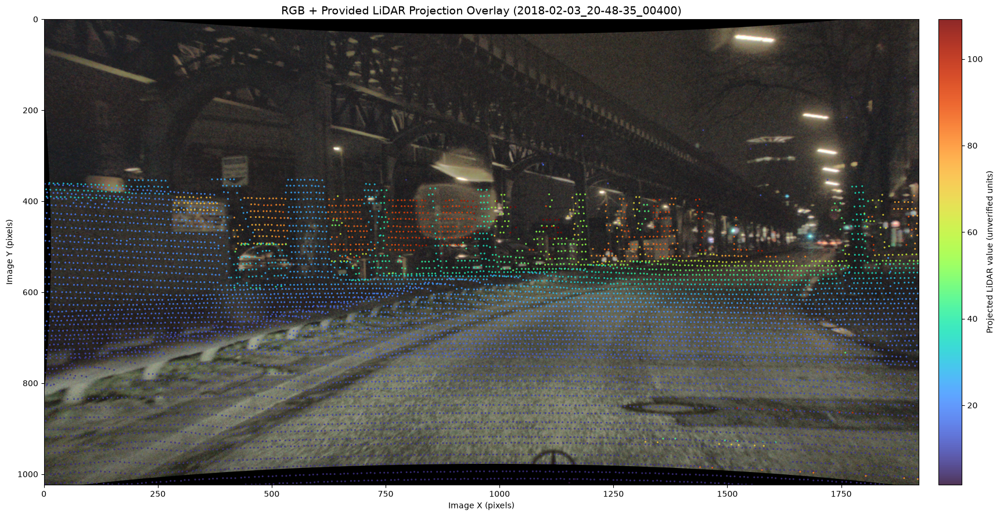

In [5]:
# Extract pixel coordinates containing valid LiDAR values
y_coords, x_coords = np.where(valid_mask)
point_values = projected_map[valid_mask]

fig, ax = plt.subplots(figsize=(18, 9))

# Display original RGB image
ax.imshow(rgb)

# Overlay projected LiDAR points
scatter = ax.scatter(
    x_coords,
    y_coords,
    c=point_values,
    cmap="turbo",
    s=5,
    alpha=0.85,
    linewidths=0
)

ax.set_title(
    f"RGB + Provided LiDAR Projection Overlay ({SAMPLE_FRAME_ID})",
    fontsize=14
)

ax.set_xlabel("Image X (pixels)")
ax.set_ylabel("Image Y (pixels)")

cbar = plt.colorbar(scatter, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Projected LiDAR value (unverified units)")

ax.set_xlim(0, rgb.shape[1])
ax.set_ylim(rgb.shape[0], 0)

plt.tight_layout()
plt.show()

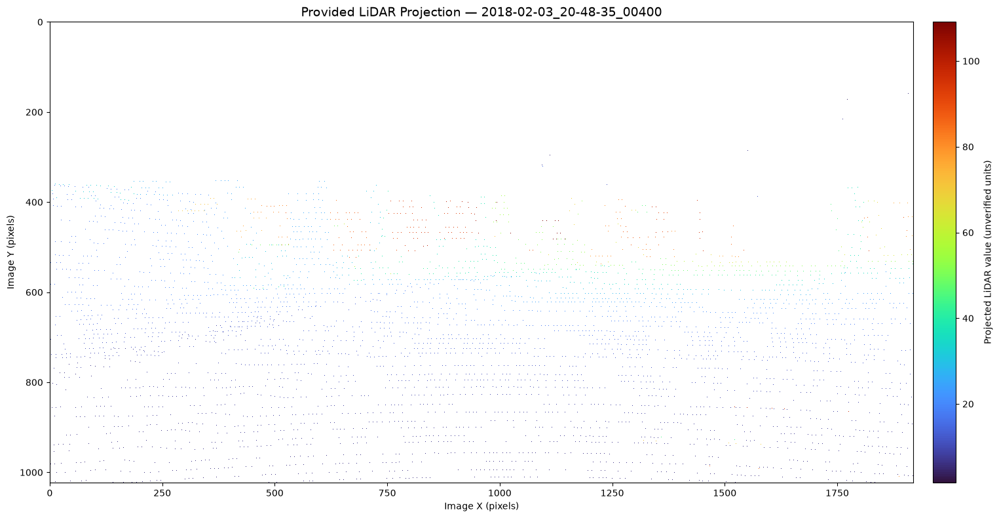

In [4]:
# Mask invalid values
projected_display = np.where(
    valid_mask,
    projected_map,
    np.nan
)

fig, ax = plt.subplots(figsize=(16, 8))

im = ax.imshow(
    projected_display,
    cmap="turbo",
    interpolation="nearest"
)

ax.set_title(
    f"Provided LiDAR Projection — {SAMPLE_FRAME_ID}",
    fontsize=14
)
ax.set_xlabel("Image X (pixels)")
ax.set_ylabel("Image Y (pixels)")

cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Projected LiDAR value (unverified units)")

plt.tight_layout()
plt.show()

## 3. Calibration inspection

### 3.1 Transform tree

The full transform tree is inspected to identify the sensor frames and their common parent frame. The relevant frames are `lidar_hdl64_s3_roof` and `cam_stereo_left_optical`.

In [6]:
import json

CALIBRATION_PATH = (
    DATASET_DIR / "downloads" / "calibration" / "calib_tf_tree_full.json"
)

with open(CALIBRATION_PATH, "r") as f:
    tf_data = json.load(f)

print("Number of transformations:", len(tf_data))

for i, item in enumerate(tf_data):
    parent = item["header"]["frame_id"]
    child = item["child_frame_id"]

    print(f"{i:02d}: {parent}  -->  {child}")

Number of transformations: 31
00: cam_stereo_left_optical  -->  cam_stereo_left_visual
01: body  -->  lidar_hdl64_s3_roof
02: body  -->  cam_stereo_left_optical
03: body  -->  lidar_vlp32_roof
04: cam_stereo_left_optical  -->  cam_stereo_right_optical
05: body  -->  radar_astyx
06: body  -->  kingpin_wheel_front_right
07: body  -->  bwv_cam_optical
08: base_link  -->  body
09: body  -->  wheel_rear_left
10: axle_front_center  -->  car_cad
11: body  -->  adma_gps_antenna
12: body  -->  adma_case
13: body  -->  lidar_hdl64_s2_roof
14: kingpin_wheel_front_left  -->  wheel_front_left
15: lidar_hdl64_s2_roof  -->  lidar_hdl64_s2_roof_head
16: cam_stereo_right_optical  -->  cam_stereo_right_visual
17: body  -->  radar_ars300
18: body  -->  kingpin_wheel_front_left
19: body  -->  wheel_rear_right
20: body  -->  axle_front_center
21: body  -->  bwv_laser_left
22: body  -->  radar_dtr
23: adma_case  -->  adma_body
24: kingpin_wheel_front_right  -->  wheel_front_right
25: body  -->  axle_rear_ce

In [7]:
relevant_frames = {
    "lidar_hdl64_s3_roof",
    "cam_stereo_left_optical"
}

for item in tf_data:
    child = item["child_frame_id"]

    if child in relevant_frames:
        print(f"\nChild frame: {child}")
        print(f"Parent frame: {item['header']['frame_id']}")

        print("Translation:")
        print(item["transform"]["translation"])

        print("Rotation (quaternion):")
        print(item["transform"]["rotation"])


Child frame: lidar_hdl64_s3_roof
Parent frame: body
Translation:
{'y': -0.00125, 'x': 1.4185, 'z': 1.30225}
Rotation (quaternion):
{'y': -0.006999886834005389, 'x': -2.7999696667896407e-05, 'z': -0.003999891334003365, 'w': 0.9999675003067072}

Child frame: cam_stereo_left_optical
Parent frame: body
Translation:
{'y': 0.086961, 'x': 2.11688, 'z': 0.89075}
Rotation (quaternion):
{'y': 0.49859243146922594, 'x': -0.49797334687178507, 'z': -0.5013107060281987, 'w': 0.5021112517245825}


### 3.2 Camera calibration

The camera calibration provides `K`, `D`, `R` and `P`:

- `K`: intrinsic matrix for the camera model;
- `D`: distortion coefficients;
- `R`: rectification rotation;
- `P`: projection matrix used for the rectified image geometry.

The RGB files in `cam_stereo_left_lut` are rectified images. This matters because applying rectification a second time during projection would be incorrect.

In [8]:
CAMERA_CALIBRATION_PATH = (
    DATASET_DIR / "downloads" / "calibration" / "calib_cam_stereo_left.json"
)

with open(CAMERA_CALIBRATION_PATH, "r") as f:
    camera_calibration = json.load(f)

print(json.dumps(camera_calibration, indent=2))

{
  "roi": {
    "width": 0,
    "do_rectify": false,
    "y_offset": 0,
    "x_offset": 0,
    "height": 0
  },
  "D": [
    -0.5675749999999999,
    0.0,
    0.0,
    0.0,
    0.0
  ],
  "P": [
    2355.722801,
    0.0,
    988.138054,
    0.0,
    0.0,
    2355.722801,
    508.051838,
    0.0,
    0.0,
    0.0,
    1.0,
    0.0
  ],
  "width": 1920,
  "K": [
    2612.86,
    0.0,
    966.525,
    0.0,
    2612.86,
    508.297,
    0.0,
    0.0,
    1.0
  ],
  "height": 1024,
  "header": {
    "stamp": {
      "secs": 1517930040,
      "nsecs": 610230780
    },
    "frame_id": "cam_stereo_left_optical",
    "seq": 259044
  },
  "R": [
    0.9999929999999999,
    -0.001011,
    -0.003531,
    0.0010019999999999999,
    0.999996,
    -0.002456,
    0.0035329999999999997,
    0.002453,
    0.999991
  ],
  "binning_y": 0,
  "binning_x": 0,
  "distortion_model": "plumb_bob"
}


In [9]:
import numpy as np

P = np.array(camera_calibration["P"]).reshape(3, 4)
D = np.array(camera_calibration["D"])

K = P[:, :3]

print("Projection matrix P:")
print(P)

print("\nIntrinsic matrix K:")
print(K)

print("\nDistortion coefficients D:")
print(D)

print("\nDistortion model:")
print(camera_calibration["distortion_model"])

print("\nImage dimensions:")
print(
    camera_calibration.get("width"),
    "x",
    camera_calibration.get("height")
)

print("\nBinning:")
print(
    "x:", camera_calibration.get("binning_x"),
    "y:", camera_calibration.get("binning_y")
)

Projection matrix P:
[[2.35572280e+03 0.00000000e+00 9.88138054e+02 0.00000000e+00]
 [0.00000000e+00 2.35572280e+03 5.08051838e+02 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00 0.00000000e+00]]

Intrinsic matrix K:
[[2.35572280e+03 0.00000000e+00 9.88138054e+02]
 [0.00000000e+00 2.35572280e+03 5.08051838e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Distortion coefficients D:
[-0.567575  0.        0.        0.        0.      ]

Distortion model:
plumb_bob

Image dimensions:
1920 x 1024

Binning:
x: 0 y: 0


### 3.3 Supporting inspection of image preparation

The following cells inspect the local directory and available dataset documentation for camera LUT and rectification references. They are retained as part of the investigation trail.

In [11]:
# Inspect the RGB camera directory structure

print("Camera directory:", CAMERA_DIR)

for path in sorted(CAMERA_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(CAMERA_DIR))
        if sum(1 for _ in CAMERA_DIR.rglob("*")) > 100:
            break

# Inspect files and folders associated with the camera images
for path in sorted(DATASET_DIR.rglob("*")):
    if path.is_file() and (
        "cam_stereo_left" in str(path).lower()
        or "rectif" in str(path).lower()
        or "lut" in str(path).lower()
    ):
        print(path.relative_to(DATASET_DIR))

Camera directory: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/cam_stereo_left_lut
cam_stereo_left_lut/2018-02-03_20-48-35_00400.png
downloads/calibration/calib_cam_stereo_left.json
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z01
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z02
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z03
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z04
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z05
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z06
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z07
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z08
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z09
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z10
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z11
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z12
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z13
downloads/cam_stereo_left_lut/cam_stereo_left_lut.z14
downloads/cam_stereo_left_lu

In [12]:
# Search local dataset documentation for camera LUT / rectification references
for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".md", ".txt", ".yaml", ".yml", ".json", ".xml"
    }:
        print(path.relative_to(DATASET_DIR))

extracted/gt_labels/cam_left_labels_TMP/2018-12-09_11-51-37_06800.txt
extracted/gt_labels/cam_left_labels_TMP/2018-12-20_14-44-46_01000.txt
extracted/gt_labels/cam_left_labels_TMP/2019-01-09_11-33-12_03200.txt
extracted/gt_labels/cam_left_labels_TMP/2018-02-08_15-37-06_00700.txt
extracted/gt_labels/cam_left_labels_TMP/2018-12-21_17-27-02_00700.txt
extracted/gt_labels/cam_left_labels_TMP/2018-10-08_08-50-46_06200.txt
extracted/gt_labels/cam_left_labels_TMP/2019-01-09_18-03-45_01000.txt
extracted/gt_labels/cam_left_labels_TMP/2018-02-08_15-35-44_00200.txt
extracted/gt_labels/cam_left_labels_TMP/2018-02-03_22-51-58_00010.txt
extracted/gt_labels/cam_left_labels_TMP/2018-10-29_14-30-29_00620.txt
extracted/gt_labels/cam_left_labels_TMP/2019-05-02_17-25-59_00510.txt
extracted/gt_labels/cam_left_labels_TMP/2018-02-06_13-51-25_00100.txt
extracted/gt_labels/cam_left_labels_TMP/2018-02-04_21-44-44_00000.txt
extracted/gt_labels/cam_left_labels_TMP/2018-12-20_12-02-06_01500.txt
extracted/gt_labels/

### 3.4 Calibration matrices

The complete camera matrices are printed for direct inspection and to avoid relying only on abbreviated JSON output.

In [13]:
# Inspect the complete camera calibration matrices

for key in ["K", "D", "R", "P"]:
    print(f"\n{key}:")
    print(np.array(camera_calibration[key]).reshape(
        (3, 3) if key in ["K", "R"] else
        (3, 4) if key == "P" else (-1,)
    ))


K:
[[2.61286e+03 0.00000e+00 9.66525e+02]
 [0.00000e+00 2.61286e+03 5.08297e+02]
 [0.00000e+00 0.00000e+00 1.00000e+00]]

D:
[-0.567575  0.        0.        0.        0.      ]

R:
[[ 0.999993 -0.001011 -0.003531]
 [ 0.001002  0.999996 -0.002456]
 [ 0.003533  0.002453  0.999991]]

P:
[[2.35572280e+03 0.00000000e+00 9.88138054e+02 0.00000000e+00]
 [0.00000000e+00 2.35572280e+03 5.08051838e+02 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00 0.00000000e+00]]


## 4. Recover the LiDAR-to-camera extrinsic transformation

The transform tree stores each sensor pose relative to `body`. The homogeneous transformation from LiDAR coordinates to camera coordinates is computed as:

\[
T_{camera\leftarrow lidar}
=
T_{body\leftarrow camera}^{-1}
T_{body\leftarrow lidar}
\]

Quaternions are converted using SciPy's `[x, y, z, w]` convention. Translation units are assumed to be metres based on the calibration convention, but this assumption should remain explicit in reporting.

In [14]:
import json
from pathlib import Path

calib_tf_path = (
    DATASET_DIR / "downloads" / "calibration" / "calib_tf_tree_full.json"
)

with open(calib_tf_path, "r") as f:
    tf_data = json.load(f)

# Inspect the two sensor transforms
target_frames = {
    "lidar_hdl64_s3_roof",
    "cam_stereo_left_optical"
}

for entry in tf_data:
    if entry["child_frame_id"] in target_frames:
        print("\nParent:", entry["header"]["frame_id"])
        print("Child:", entry["child_frame_id"])
        print("Translation:", entry["transform"]["translation"])
        print("Quaternion:", entry["transform"]["rotation"])


Parent: body
Child: lidar_hdl64_s3_roof
Translation: {'y': -0.00125, 'x': 1.4185, 'z': 1.30225}
Quaternion: {'y': -0.006999886834005389, 'x': -2.7999696667896407e-05, 'z': -0.003999891334003365, 'w': 0.9999675003067072}

Parent: body
Child: cam_stereo_left_optical
Translation: {'y': 0.086961, 'x': 2.11688, 'z': 0.89075}
Quaternion: {'y': 0.49859243146922594, 'x': -0.49797334687178507, 'z': -0.5013107060281987, 'w': 0.5021112517245825}


In [15]:
import numpy as np
from scipy.spatial.transform import Rotation

def transform_to_matrix(translation, quaternion):
    """
    Build a 4x4 homogeneous transformation matrix.

    Quaternion convention: x, y, z, w
    """
    q = [
        quaternion["x"],
        quaternion["y"],
        quaternion["z"],
        quaternion["w"]
    ]

    rotation_matrix = Rotation.from_quat(q).as_matrix()

    T = np.eye(4)
    T[:3, :3] = rotation_matrix
    T[:3, 3] = [
        translation["x"],
        translation["y"],
        translation["z"]
    ]

    return T


# Extract sensor transforms
lidar_entry = next(
    e for e in tf_data
    if e["child_frame_id"] == "lidar_hdl64_s3_roof"
)

camera_entry = next(
    e for e in tf_data
    if e["child_frame_id"] == "cam_stereo_left_optical"
)

# Build homogeneous matrices
T_body_lidar = transform_to_matrix(
    lidar_entry["transform"]["translation"],
    lidar_entry["transform"]["rotation"]
)

T_body_camera = transform_to_matrix(
    camera_entry["transform"]["translation"],
    camera_entry["transform"]["rotation"]
)

print("T_body_lidar:")
print(np.round(T_body_lidar, 6))

print("\nT_body_camera:")
print(np.round(T_body_camera, 6))

T_body_lidar:
[[ 9.99870e-01  8.00000e-03 -1.39990e-02  1.41850e+00]
 [-7.99900e-03  9.99968e-01  1.12000e-04 -1.25000e-03]
 [ 1.40000e-02  0.00000e+00  9.99902e-01  1.30225e+00]
 [ 0.00000e+00  0.00000e+00  0.00000e+00  1.00000e+00]]

T_body_camera:
[[ 1.86000e-04  6.85600e-03  9.99976e-01  2.11688e+00]
 [-9.99999e-01  1.42000e-03  1.77000e-04  8.69610e-02]
 [-1.41900e-03 -9.99975e-01  6.85600e-03  8.90750e-01]
 [ 0.00000e+00  0.00000e+00  0.00000e+00  1.00000e+00]]


In [16]:
# Transform LiDAR coordinates into camera coordinates
T_camera_lidar = np.linalg.inv(T_body_camera) @ T_body_lidar

print("T_camera_lidar:")
print(np.round(T_camera_lidar, 6))

# Separate rotation and translation
R_camera_lidar = T_camera_lidar[:3, :3]
t_camera_lidar = T_camera_lidar[:3, 3]

print("\nRotation:")
print(np.round(R_camera_lidar, 6))

print("\nTranslation (meters, assuming calibration units are meters):")
print(np.round(t_camera_lidar, 6))

T_camera_lidar:
[[ 0.008166 -0.999965 -0.001533  0.087497]
 [-0.007155  0.001475 -0.999973 -0.416403]
 [ 0.999941  0.008176 -0.007143 -0.695558]
 [ 0.        0.        0.        1.      ]]

Rotation:
[[ 0.008166 -0.999965 -0.001533]
 [-0.007155  0.001475 -0.999973]
 [ 0.999941  0.008176 -0.007143]]

Translation (meters, assuming calibration units are meters):
[ 0.087497 -0.416403 -0.695558]


In [17]:
# Synthetic LiDAR point located in front of the vehicle
test_point_lidar = np.array([10.0, 0.0, 0.0, 1.0])

# Transform into camera coordinates
test_point_camera = T_camera_lidar @ test_point_lidar

print("LiDAR point:", test_point_lidar[:3])
print("Camera point:", test_point_camera[:3])

print("\nCamera depth (Z):", test_point_camera[2])

if test_point_camera[2] > 0:
    print("VALID: Point is in front of the camera.")
else:
    print("INVALID: Point is behind the camera.")

LiDAR point: [10.  0.  0.]
Camera point: [ 0.16915246 -0.48795772  9.3038528 ]

Camera depth (Z): 9.303852800994788
VALID: Point is in front of the camera.


## 5. First projection attempt — exploratory pipeline

The next cells preserve the first implementation rather than deleting it. This was a useful diagnostic step: it transformed points into camera coordinates, applied the camera rectification matrix `R`, and then projected them with `P`.

### Why this approach was revised

The RGB images being inspected are already rectified. The Princeton repository's `Lidar2RGB` implementation treats `P` as the rectified projection matrix and sets the additional rectification transform to identity. In other words, the repository composes:

\[
VTC = P\,T_{camera\leftarrow lidar}
\]

It does **not** apply the calibration `R` again between the extrinsic transform and `P`.

Therefore, the first approach below is retained as an exploratory historical attempt, but it is not the final projection pipeline. Applying `R` separately and then using rectified `P` risks double rectification.

In [18]:
# Load the original LiDAR point cloud
raw_lidar = np.fromfile(lidar_path, dtype=np.float32)

lidar_points = raw_lidar.reshape(-1, 5)

# Extract candidate XYZ coordinates
xyz_lidar = lidar_points[:, :3]

# Convert to homogeneous coordinates
xyz_lidar_h = np.column_stack([
    xyz_lidar,
    np.ones(len(xyz_lidar))
])

# Transform all points into camera coordinates
xyz_camera_h = (
    T_camera_lidar @ xyz_lidar_h.T
).T

xyz_camera = xyz_camera_h[:, :3]

# Check positive camera depth
positive_depth_mask = xyz_camera[:, 2] > 0

print("Total LiDAR points:", len(xyz_lidar))
print("Points in front of camera:", positive_depth_mask.sum())
print("Points behind or on camera plane:", (~positive_depth_mask).sum())

print("\nCamera-coordinate ranges:")
print("X:", xyz_camera[:, 0].min(), xyz_camera[:, 0].max())
print("Y:", xyz_camera[:, 1].min(), xyz_camera[:, 1].max())
print("Z:", xyz_camera[:, 2].min(), xyz_camera[:, 2].max())

Total LiDAR points: 110514
Points in front of camera: 51040
Points behind or on camera plane: 59474

Camera-coordinate ranges:
X: -42.77186429559897 81.20663539365431
Y: -4.944029507235748 35.29099131641423
Z: -109.63995880475441 109.17822998755419


In [19]:
# Step 1: Keep points in front of the camera
front_points = xyz_camera[positive_depth_mask]

# Step 2: Apply camera rectification rotation
R_rect = np.array(camera_calibration["R"]).reshape(3, 3)
P = np.array(camera_calibration["P"]).reshape(3, 4)

xyz_rectified = (R_rect @ front_points.T).T

# Step 3: Project 3D points using P
xyz_rectified_h = np.column_stack([
    xyz_rectified,
    np.ones(len(xyz_rectified))
])

projected_h = (P @ xyz_rectified_h.T).T

u = projected_h[:, 0] / projected_h[:, 2]
v = projected_h[:, 1] / projected_h[:, 2]

# Step 4: Check image boundaries
height, width = rgb.shape[:2]

inside_image = (
    (u >= 0) & (u < width) &
    (v >= 0) & (v < height)
)

print("Points in front of camera:", len(front_points))
print("Projected points:", len(u))
print("Points inside image:", inside_image.sum())
print("Points outside image:", (~inside_image).sum())

print("\nProjected coordinate ranges:")
print("u:", np.nanmin(u), np.nanmax(u))
print("v:", np.nanmin(v), np.nanmax(v))

Points in front of camera: 51040
Projected points: 51040
Points inside image: 8989
Points outside image: 42051

Projected coordinate ranges:
u: -145864941.98255634 65492418.027165584
v: -6176401.8521481585 4318744.682412376


In [20]:
# Apply rectification rotation
xyz_rectified = (R_rect @ front_points.T).T

# Inspect rectified depth distribution
depth = xyz_rectified[:, 2]

print("Rectified depth statistics (meters, assuming calibration units):")
print("Minimum:", np.min(depth))
print("Maximum:", np.max(depth))
print("Percentiles:", np.percentile(
    depth, [0, 1, 5, 10, 25, 50, 75, 90, 95, 99]
))

# Count points at different minimum-depth thresholds
for threshold in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]:
    count = np.sum(depth > threshold)
    print(
        f"Depth > {threshold:4.2f} m: "
        f"{count:6d} points ({count / len(depth) * 100:.2f}%)"
    )

Rectified depth statistics (meters, assuming calibration units):
Minimum: -0.0595867282253917
Maximum: 109.17445224335678
Percentiles: [-5.95867282e-02  1.18732090e-01  5.56713813e-01  9.46221423e-01
  2.37693214e+00  4.82427295e+00  9.23810917e+00  1.73687998e+01
  2.79735915e+01  8.01163965e+01]
Depth > 0.01 m:  50974 points (99.87%)
Depth > 0.10 m:  50609 points (99.16%)
Depth > 0.50 m:  48975 points (95.95%)
Depth > 1.00 m:  45686 points (89.51%)
Depth > 2.00 m:  40286 points (78.93%)
Depth > 5.00 m:  24836 points (48.66%)


In [21]:
# Keep only points with valid positive depth AFTER rectification
valid_depth_mask = xyz_rectified[:, 2] > 0.5

xyz_rectified_valid = xyz_rectified[valid_depth_mask]

# Project using the rectified camera projection matrix
P_3x3 = P[:, :3]

projected = (P_3x3 @ xyz_rectified_valid.T).T

u_filtered = projected[:, 0] / projected[:, 2]
v_filtered = projected[:, 1] / projected[:, 2]

# Check image boundaries
inside_filtered = (
    (u_filtered >= 0) & (u_filtered < width) &
    (v_filtered >= 0) & (v_filtered < height)
)

print("Points after depth filtering:", len(xyz_rectified_valid))
print("Points inside image:", inside_filtered.sum())
print("Points outside image:", (~inside_filtered).sum())

print("\nProjected coordinate ranges:")
print("u:", u_filtered.min(), u_filtered.max())
print("v:", v_filtered.min(), v_filtered.max())

Points after depth filtering: 48975
Points inside image: 8989
Points outside image: 39986

Projected coordinate ranges:
u: -110121.06739168038 83424.76353572095
v: -6037.936932170857 17501.22084134738


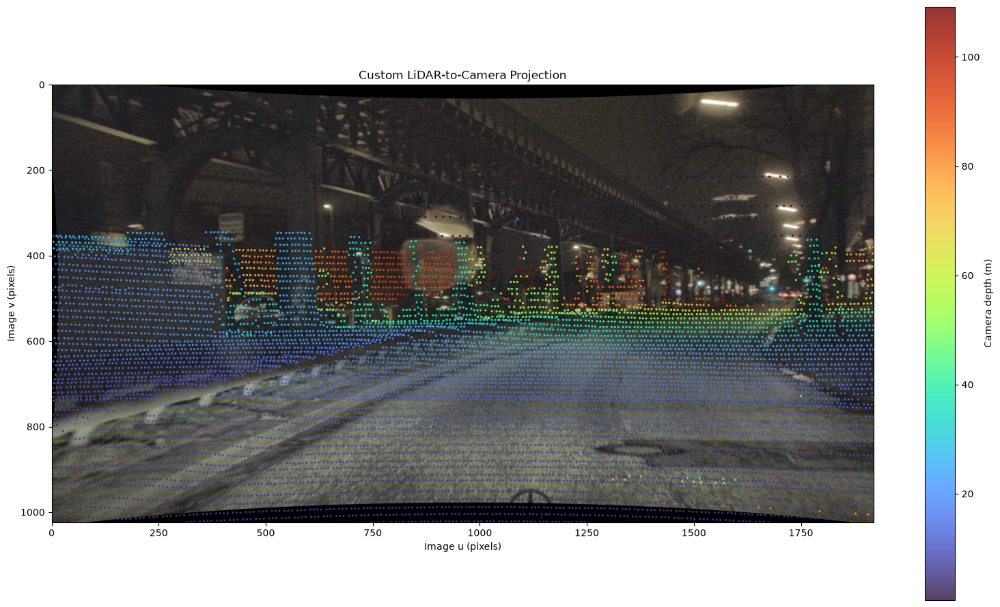

In [22]:
# Keep projected points inside the RGB image
u_inside = u_filtered[inside_filtered]
v_inside = v_filtered[inside_filtered]

depth_inside = xyz_rectified_valid[inside_filtered, 2]

# Visualize our custom LiDAR projection
plt.figure(figsize=(16, 9))
plt.imshow(rgb)

scatter = plt.scatter(
    u_inside,
    v_inside,
    c=depth_inside,
    cmap="turbo",
    s=2,
    alpha=0.8
)

plt.colorbar(scatter, label="Camera depth (m)")
plt.title("Custom LiDAR-to-Camera Projection")
plt.xlim(0, width)
plt.ylim(height, 0)
plt.xlabel("Image u (pixels)")
plt.ylabel("Image v (pixels)")
plt.tight_layout()
plt.show()

### 5.1 Initial comparison and diagnostics

The initial pixel comparison and nearest-pixel diagnostics are preserved below. They document the first attempt and help explain why the implementation was revisited.

These preliminary numbers should not be treated as the final validation result because the projection procedure was subsequently corrected after inspecting the Princeton source code.

In [23]:
# 1. Official projected LiDAR pixel locations
official_mask = np.isfinite(projected_map) & (projected_map > 0)

official_pixels = set(
    np.flatnonzero(official_mask).tolist()
)

# 2. Custom projected pixel locations
custom_u = np.rint(u_inside).astype(int)
custom_v = np.rint(v_inside).astype(int)

custom_linear = (
    custom_v * width + custom_u
)

custom_pixels = set(custom_linear.tolist())

# 3. Spatial overlap
intersection = official_pixels & custom_pixels
union = official_pixels | custom_pixels

print("Official unique pixels:", len(official_pixels))
print("Custom unique pixels:", len(custom_pixels))
print("Common pixels:", len(intersection))

print("\nSpatial agreement:")
print(f"Official pixel recall: {len(intersection) / len(official_pixels):.2%}")
print(f"Custom pixel precision: {len(intersection) / len(custom_pixels):.2%}")
print(f"IoU: {len(intersection) / len(union):.2%}")

Official unique pixels: 8618
Custom unique pixels: 8985
Common pixels: 10

Spatial agreement:
Official pixel recall: 0.12%
Custom pixel precision: 0.11%
IoU: 0.06%


In [25]:
from scipy.ndimage import distance_transform_edt

# Official valid pixels
official_mask = (
    np.isfinite(projected_map) &
    (projected_map > 0)
)

# Round custom coordinates
custom_u = np.rint(u_inside).astype(int)
custom_v = np.rint(v_inside).astype(int)

# Keep rounded coordinates strictly inside the image
valid_indices = (
    (custom_u >= 0) & (custom_u < width) &
    (custom_v >= 0) & (custom_v < height)
)

custom_u = custom_u[valid_indices]
custom_v = custom_v[valid_indices]

# Create custom binary mask
custom_mask = np.zeros((height, width), dtype=bool)
custom_mask[custom_v, custom_u] = True

# Distance maps
distance_to_official = distance_transform_edt(~official_mask)
distance_to_custom = distance_transform_edt(~custom_mask)

# Nearest-pixel distances
custom_distances = distance_to_official[custom_mask]
official_distances = distance_to_custom[official_mask]

def print_distance_stats(name, distances):
    print(f"\n{name}")
    print("Mean:", round(np.mean(distances), 3), "pixels")
    print("Median:", round(np.median(distances), 3), "pixels")
    print("Percentiles:", np.round(
        np.percentile(distances, [25, 50, 75, 90, 95, 99]), 2
    ))

print_distance_stats("Custom -> Official", custom_distances)
print_distance_stats("Official -> Custom", official_distances)

print("\nSpatial agreement within tolerance:")

for radius in [1, 2, 3, 5, 10]:
    print(
        f"{radius:2d} px | "
        f"Custom: {np.mean(custom_distances <= radius):.2%} | "
        f"Official: {np.mean(official_distances <= radius):.2%}"
    )


Custom -> Official
Mean: 7.546 pixels
Median: 6.0 pixels
Percentiles: [ 5.1   6.    6.71  7.62 10.3  70.36]

Official -> Custom
Mean: 5.65 pixels
Median: 5.831 pixels
Percentiles: [ 5.1   5.83  6.08  7.21  8.06 10.3 ]

Spatial agreement within tolerance:
 1 px | Custom: 0.66% | Official: 0.68%
 2 px | Custom: 1.64% | Official: 1.71%
 3 px | Custom: 5.26% | Official: 5.43%
 5 px | Custom: 23.30% | Official: 24.34%
10 px | Custom: 94.91% | Official: 98.87%


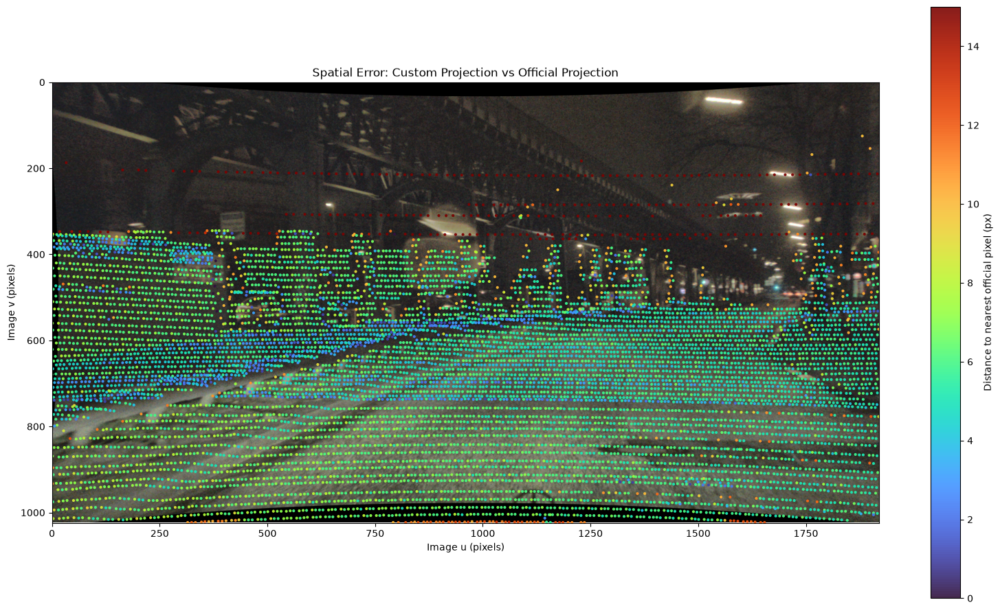

In [26]:
# Distance from every custom point to the nearest official pixel
plt.figure(figsize=(16, 9))

plt.imshow(rgb)

scatter = plt.scatter(
    np.where(custom_mask)[1],
    np.where(custom_mask)[0],
    c=custom_distances,
    cmap="turbo",
    s=4,
    vmin=0,
    vmax=15,
    alpha=0.9
)

plt.colorbar(scatter, label="Distance to nearest official pixel (px)")
plt.title("Spatial Error: Custom Projection vs Official Projection")
plt.xlim(0, width)
plt.ylim(height, 0)
plt.xlabel("Image u (pixels)")
plt.ylabel("Image v (pixels)")
plt.tight_layout()
plt.show()

In [27]:
from scipy.ndimage import distance_transform_edt

# Find nearest official pixel for every image location
distance_map, nearest_indices = distance_transform_edt(
    ~official_mask,
    return_indices=True
)

# Coordinates of custom projected pixels
custom_y, custom_x = np.where(custom_mask)

# Coordinates of their nearest official pixels
nearest_y = nearest_indices[0, custom_y, custom_x]
nearest_x = nearest_indices[1, custom_y, custom_x]

# Displacement from custom to official
dx = nearest_x - custom_x
dy = nearest_y - custom_y

print("Horizontal displacement (official - custom):")
print("Median:", np.median(dx))
print("Mean:", np.mean(dx))
print("Percentiles:", np.percentile(dx, [10, 25, 50, 75, 90]))

print("\nVertical displacement (official - custom):")
print("Median:", np.median(dy))
print("Mean:", np.mean(dy))
print("Percentiles:", np.percentile(dy, [10, 25, 50, 75, 90]))

print("\nDisplacement magnitude:")
magnitude = np.sqrt(dx**2 + dy**2)
print("Median:", np.median(magnitude))
print("90th percentile:", np.percentile(magnitude, 90))

Horizontal displacement (official - custom):
Median: 0.0
Mean: -0.2528133704735376
Percentiles: [-4. -3.  0.  1.  2.]

Vertical displacement (official - custom):
Median: 5.0
Mean: 3.872869080779944
Percentiles: [-5. -2.  5.  6.  7.]

Displacement magnitude:
Median: 6.0
90th percentile: 7.615773105863909


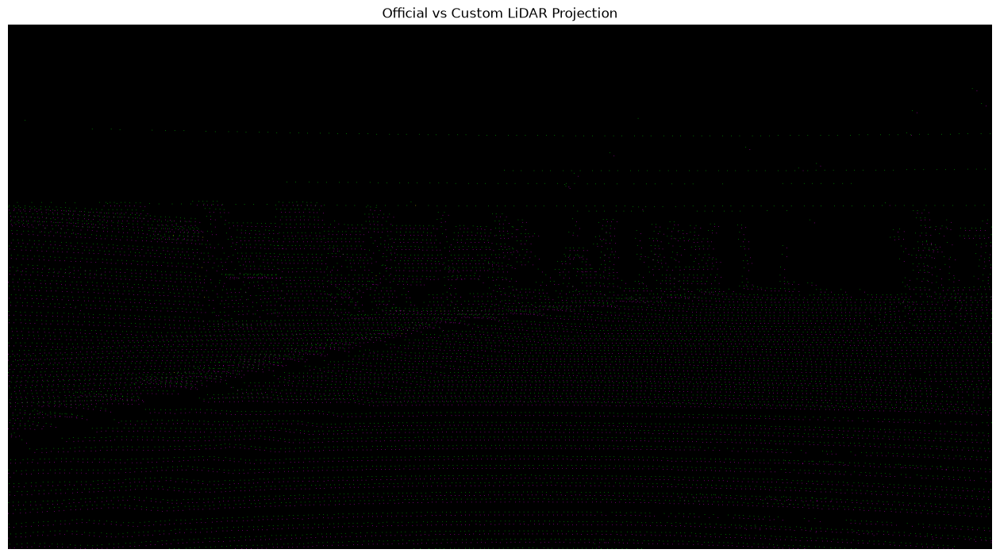

In [29]:
# Create an RGB comparison image
comparison = np.zeros((height, width, 3), dtype=np.uint8)

# Official projection: magenta
comparison[official_mask] = [255, 0, 255]

# Custom projection: green
comparison[custom_mask] = [0, 255, 0]

# Shared pixels: yellow
comparison[official_mask & custom_mask] = [255, 255, 0]

plt.figure(figsize=(16, 9))
plt.imshow(comparison)
plt.title("Official vs Custom LiDAR Projection")
plt.axis("off")
plt.show()

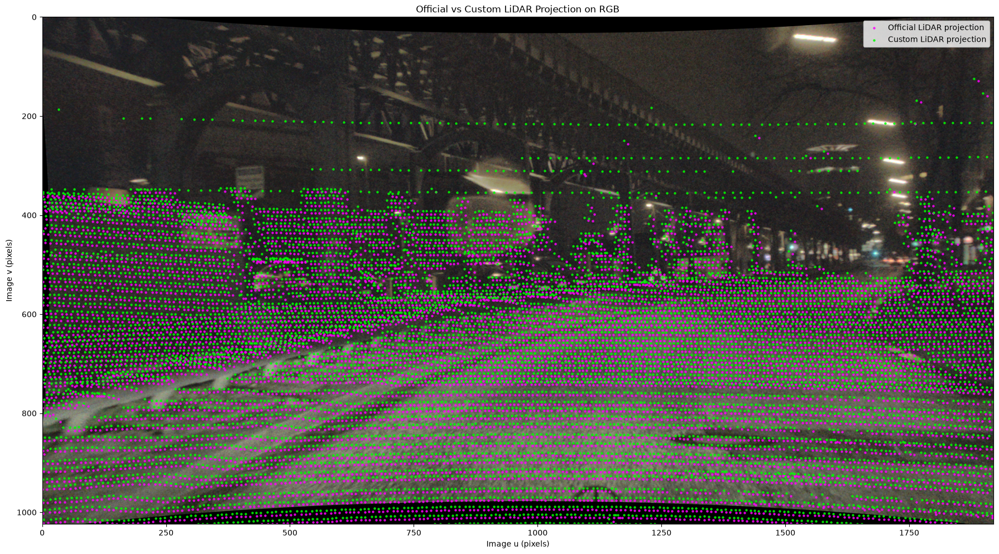

In [30]:
# Create RGB overlay
plt.figure(figsize=(18, 10))
plt.imshow(rgb)

# Official projection: magenta
official_y, official_x = np.where(official_mask)

plt.scatter(
    official_x,
    official_y,
    c="magenta",
    s=5,
    alpha=0.75,
    label="Official LiDAR projection"
)

# Custom projection: green
custom_y, custom_x = np.where(custom_mask)

plt.scatter(
    custom_x,
    custom_y,
    c="lime",
    s=5,
    alpha=0.75,
    label="Custom LiDAR projection"
)

plt.title("Official vs Custom LiDAR Projection on RGB")
plt.xlabel("Image u (pixels)")
plt.ylabel("Image v (pixels)")
plt.xlim(0, width)
plt.ylim(height, 0)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

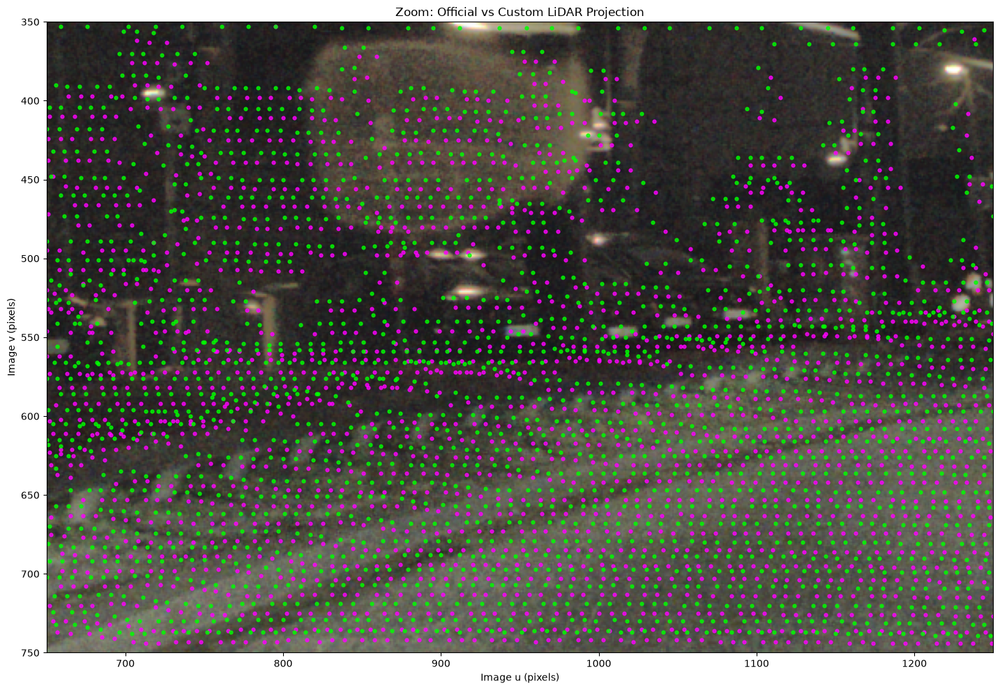

In [31]:
# Define a region of interest (ROI)
x_min, x_max = 650, 1250
y_min, y_max = 350, 750

plt.figure(figsize=(16, 10))
plt.imshow(rgb)

plt.scatter(
    official_x,
    official_y,
    c="magenta",
    s=12,
    alpha=0.8
)

plt.scatter(
    custom_x,
    custom_y,
    c="lime",
    s=12,
    alpha=0.8
)

plt.xlim(x_min, x_max)
plt.ylim(y_max, y_min)
plt.title("Zoom: Official vs Custom LiDAR Projection")
plt.xlabel("Image u (pixels)")
plt.ylabel("Image v (pixels)")
plt.tight_layout()
plt.show()

## 6. Revised projection — reproduce the Princeton repository logic

Inspection of the Princeton `SeeingThroughFog` repository showed that the projection matrix is formed as:

\[
VTC = P\,T_{camera\leftarrow lidar}
\]

The repository uses the LiDAR forward-coordinate filter `x > 2.5`, performs perspective division, keeps points with positive projected depth and image coordinates inside the image, and converts pixel coordinates to `int32`. This conversion truncates fractional pixel coordinates rather than rounding them.

The next cell implements that procedure. This is the canonical custom projection used for the subsequent comparisons in this notebook.

In [32]:
# --------------------------------------------------
# Reproduce the official Princeton projection logic
# --------------------------------------------------

# 1. Build the official Velodyne-to-camera projection matrix
# P already incorporates camera rectification.
vtc = P @ T_camera_lidar

# 2. Apply the official LiDAR-coordinate filter
official_lidar_filter = xyz_lidar[:, 0] > 2.5

xyz_lidar_filtered = xyz_lidar[official_lidar_filter]

# 3. Convert points to homogeneous coordinates
xyz_lidar_h_filtered = np.column_stack([
    xyz_lidar_filtered,
    np.ones(len(xyz_lidar_filtered))
])

# 4. Project directly using vtc
projected_h_official = (
    vtc @ xyz_lidar_h_filtered.T
).T

# 5. Apply perspective division
u_official_custom = (
    projected_h_official[:, 0] /
    projected_h_official[:, 2]
)

v_official_custom = (
    projected_h_official[:, 1] /
    projected_h_official[:, 2]
)

# 6. Apply the positive-depth and image-boundary filters
z_official_custom = projected_h_official[:, 2]

valid_official_custom = (
    (z_official_custom > 0) &
    (u_official_custom >= 0) &
    (u_official_custom < width) &
    (v_official_custom >= 0) &
    (v_official_custom < height)
)

# 7. Princeton converts projected coordinates to int32,
# which truncates rather than rounds.
u_official_pixels = (
    u_official_custom[valid_official_custom]
    .astype(np.int32)
)

v_official_pixels = (
    v_official_custom[valid_official_custom]
    .astype(np.int32)
)

# 8. Create a binary projection mask
official_method_mask = np.zeros(
    (height, width),
    dtype=bool
)

official_method_mask[
    v_official_pixels,
    u_official_pixels
] = True

print("Original LiDAR points:", len(xyz_lidar))
print("After Princeton X > 2.5 filter:", len(xyz_lidar_filtered))
print("Points projected inside RGB:", len(u_official_pixels))
print("Unique projected pixels:", official_method_mask.sum())

print("\nCoordinate ranges:")
print("u:", u_official_pixels.min(), u_official_pixels.max())
print("v:", v_official_pixels.min(), v_official_pixels.max())

Original LiDAR points: 110514
After Princeton X > 2.5 filter: 41268
Points projected inside RGB: 8618
Unique projected pixels: 8610

Coordinate ranges:
u: 0 1919
v: 129 1023


Official NPZ unique pixels: 8618
Princeton-method unique pixels: 8610
Common pixels: 2202

Spatial agreement:
Official recall: 25.55%
Custom precision: 25.57%
IoU: 14.65%


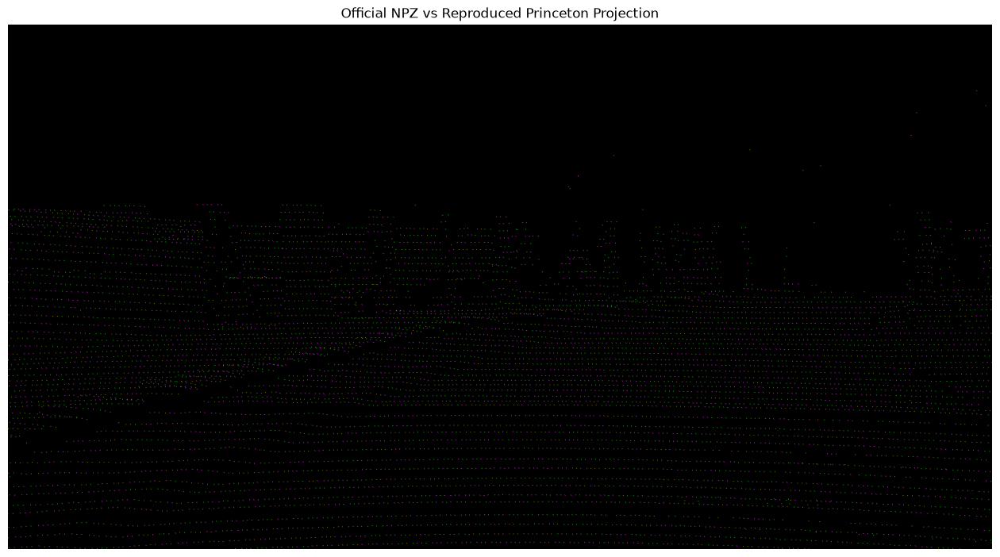

In [33]:
# Compare Princeton-method projection with official NPZ

intersection = official_method_mask & official_mask
union = official_method_mask | official_mask

common_pixels = intersection.sum()
official_pixels = official_mask.sum()
custom_pixels = official_method_mask.sum()

print("Official NPZ unique pixels:", official_pixels)
print("Princeton-method unique pixels:", custom_pixels)
print("Common pixels:", common_pixels)

print("\nSpatial agreement:")
print(f"Official recall: {common_pixels / official_pixels:.2%}")
print(f"Custom precision: {common_pixels / custom_pixels:.2%}")
print(f"IoU: {common_pixels / union.sum():.2%}")

# Visual comparison
comparison = np.zeros((height, width, 3), dtype=np.uint8)

comparison[official_mask] = [255, 0, 255]          # Magenta
comparison[official_method_mask] = [0, 255, 0]     # Green
comparison[intersection] = [255, 255, 0]           # Yellow

plt.figure(figsize=(16, 9))
plt.imshow(comparison)
plt.title("Official NPZ vs Reproduced Princeton Projection")
plt.axis("off")
plt.show()

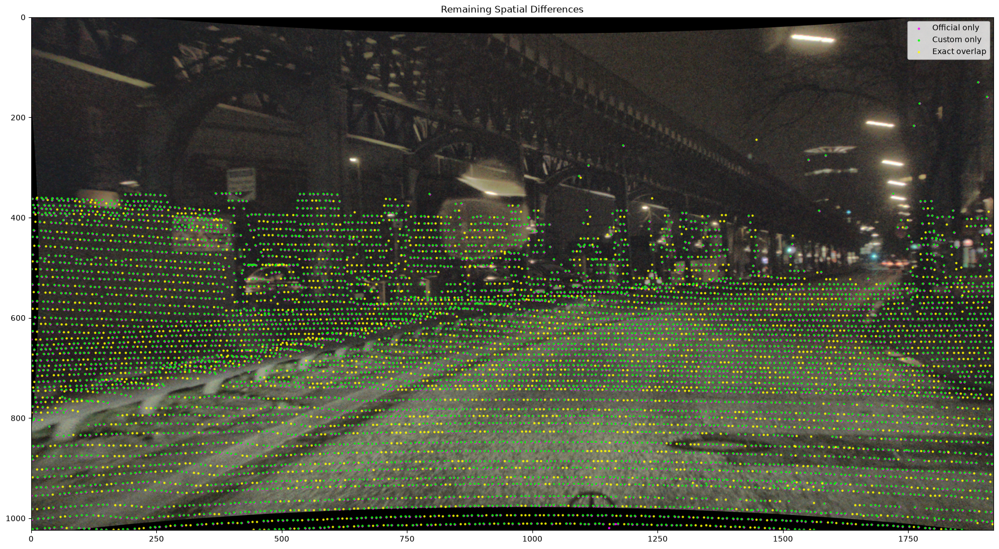

Exact overlap: 2202
Official only: 6416
Custom only: 6408


In [34]:
# Create a detailed disagreement map
comparison = np.zeros((height, width, 3), dtype=np.uint8)

common = official_mask & official_method_mask
official_only = official_mask & ~official_method_mask
custom_only = official_method_mask & ~official_mask

comparison[common] = [255, 255, 0]
comparison[official_only] = [255, 0, 255]
comparison[custom_only] = [0, 255, 0]

# Display on RGB
plt.figure(figsize=(18, 10))
plt.imshow(rgb)

official_y, official_x = np.where(official_only)
custom_y, custom_x = np.where(custom_only)
common_y, common_x = np.where(common)

plt.scatter(
    official_x, official_y,
    c="magenta", s=4, alpha=0.8,
    label="Official only"
)

plt.scatter(
    custom_x, custom_y,
    c="lime", s=4, alpha=0.8,
    label="Custom only"
)

plt.scatter(
    common_x, common_y,
    c="yellow", s=4, alpha=0.8,
    label="Exact overlap"
)

plt.xlim(0, width)
plt.ylim(height, 0)
plt.title("Remaining Spatial Differences")
plt.legend()
plt.tight_layout()
plt.show()

print("Exact overlap:", common.sum())
print("Official only:", official_only.sum())
print("Custom only:", custom_only.sum())

## 7. Multi-frame validation

A single frame can be misleading. Three frames were selected to test whether the revised projection behaves consistently across different scenes and capture dates.

The reusable function below:
- loads the original `.bin`;
- extracts candidate XYZ;
- applies the forward filter;
- projects using `VTC`;
- filters positive depth and image bounds;
- truncates projected coordinates to integer pixels;
- returns a binary mask and basic point counts.

The function is intentionally aligned with the repository's projection logic. It does not claim one-to-one physical correspondence between every pixel in the custom and official maps.


Frame: 2018-10-29_16-42-03_00310
RGB: FOUND
LiDAR: FOUND

Frame: 2018-02-06_14-25-51_00400
RGB: FOUND
LiDAR: FOUND

Frame: 2019-09-11_16-39-41_01770
RGB: FOUND
LiDAR: FOUND


,frame_id,lidar_points,filtered_points,projected_points,unique_pixels,coverage_pct
0,2018-10-29_16-42-03_00310,29735,13745,2379,2378,0.121
1,2018-02-06_14-25-51_00400,55419,21775,4073,4073,0.207
2,2019-09-11_16-39-41_01770,55602,20026,4114,4114,0.209


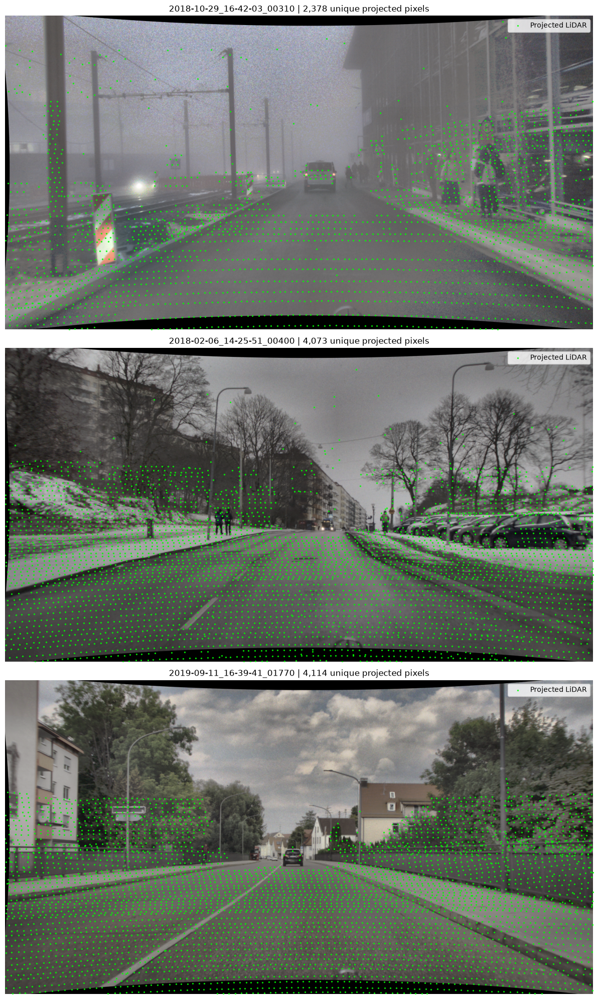

In [38]:
# Frames selected for multi-frame validation
validation_frames = [
    "2018-10-29_16-42-03_00310",
    "2018-02-06_14-25-51_00400",
    "2019-09-11_16-39-41_01770",
]

for frame_id in validation_frames:
    rgb_files = list(CAMERA_DIR.rglob(f"{frame_id}.png"))
    lidar_files = list(LIDAR_DIR.rglob(f"{frame_id}.bin"))

    print(f"\nFrame: {frame_id}")
    print("RGB:", "FOUND" if len(rgb_files) == 1 else f"{len(rgb_files)} matches")
    print("LiDAR:", "FOUND" if len(lidar_files) == 1 else f"{len(lidar_files)} matches")


def project_lidar_to_camera(lidar_path, vtc, image_shape, min_x=2.5):
    """
    Project a LiDAR point cloud into the camera image.

    Follows the projection logic found in Princeton's
    SeeingThroughFog Lidar2RGB implementation.
    """

    # Load original LiDAR data
    raw = np.fromfile(lidar_path, dtype=np.float32)
    lidar = raw.reshape(-1, 5)

    # Extract candidate XYZ coordinates and apply official filter
    xyz = lidar[:, :3]
    valid_lidar = xyz[:, 0] > min_x
    xyz_filtered = xyz[valid_lidar]

    # Homogeneous coordinates
    xyz_h = np.column_stack([
        xyz_filtered,
        np.ones(len(xyz_filtered))
    ])

    # Project using VTC
    projected_h = (vtc @ xyz_h.T).T

    # Positive camera depth
    positive_depth = projected_h[:, 2] > 0

    projected_h = projected_h[positive_depth]

    # Perspective division
    u = projected_h[:, 0] / projected_h[:, 2]
    v = projected_h[:, 1] / projected_h[:, 2]

    height, width = image_shape[:2]

    # Keep points inside image boundaries
    inside = (
        (u >= 0) & (u < width) &
        (v >= 0) & (v < height)
    )

    # Match Princeton's integer conversion
    u_pixels = u[inside].astype(np.int32)
    v_pixels = v[inside].astype(np.int32)

    # Binary projection mask
    mask = np.zeros((height, width), dtype=bool)
    mask[v_pixels, u_pixels] = True

    return {
        "mask": mask,
        "u": u_pixels,
        "v": v_pixels,
        "lidar_points": len(lidar),
        "filtered_points": len(xyz_filtered),
        "projected_points": len(u_pixels),
        "unique_pixels": int(mask.sum())
    }

import pandas as pd

validation_results = []
validation_masks = {}
validation_images = {}

for frame_id in validation_frames:

    rgb_path = list(CAMERA_DIR.rglob(f"{frame_id}.png"))[0]
    lidar_path_frame = list(LIDAR_DIR.rglob(f"{frame_id}.bin"))[0]

    # Load RGB
    image = np.array(Image.open(rgb_path).convert("RGB"))

    # Project LiDAR
    result = project_lidar_to_camera(
        lidar_path=lidar_path_frame,
        vtc=vtc,
        image_shape=image.shape
    )

    validation_masks[frame_id] = result["mask"]
    validation_images[frame_id] = image

    validation_results.append({
        "frame_id": frame_id,
        "lidar_points": result["lidar_points"],
        "filtered_points": result["filtered_points"],
        "projected_points": result["projected_points"],
        "unique_pixels": result["unique_pixels"],
        "coverage_pct": (
            result["unique_pixels"] /
            (image.shape[0] * image.shape[1]) * 100
        )
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(3))

fig, axes = plt.subplots(3, 1, figsize=(18, 20))

for ax, frame_id in zip(axes, validation_frames):

    image = validation_images[frame_id]
    mask = validation_masks[frame_id]

    # RGB image
    ax.imshow(image)

    # LiDAR projection
    y, x = np.where(mask)

    ax.scatter(
        x, y,
        c="lime",
        s=2,
        alpha=0.75,
        label="Projected LiDAR"
    )

    ax.set_title(
        f"{frame_id} | {len(x):,} unique projected pixels"
    )
    ax.set_xlim(0, image.shape[1])
    ax.set_ylim(image.shape[0], 0)
    ax.legend(loc="upper right")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 7.1 Confirm the selected frame files

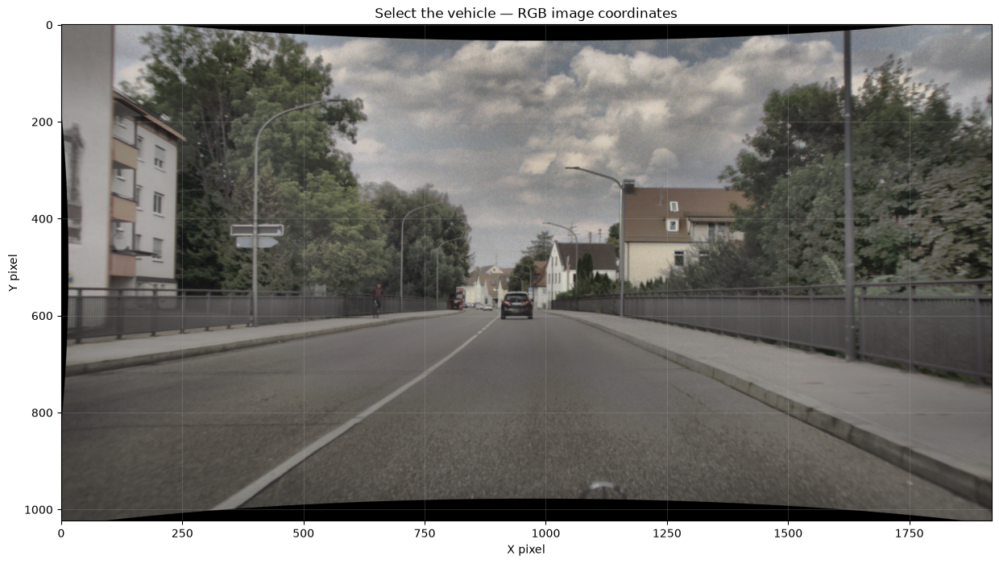

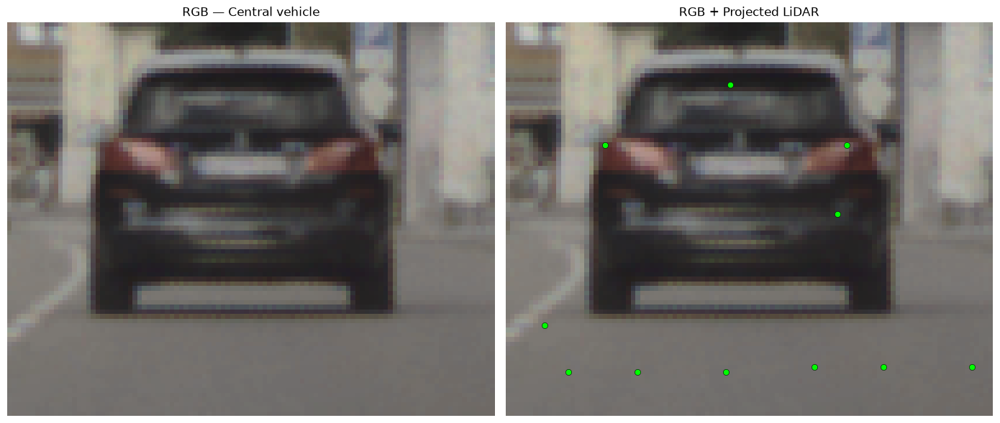

Projected LiDAR pixels inside crop: 11


In [43]:
fig, ax = plt.subplots(figsize=(16, 8))

ax.imshow(car_rgb)

# Display image coordinates
ax.set_title("Select the vehicle — RGB image coordinates")
ax.set_xlabel("X pixel")
ax.set_ylabel("Y pixel")

ax.grid(alpha=0.2)
plt.show()

# Approximate bounding region of the central car
x1, y1 = 890, 545
x2, y2 = 995, 630

vehicle_rgb = car_rgb[y1:y2, x1:x2]
vehicle_mask = car_mask[y1:y2, x1:x2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# RGB only
axes[0].imshow(vehicle_rgb)
axes[0].set_title("RGB — Central vehicle")
axes[0].axis("off")

# RGB + LiDAR
axes[1].imshow(vehicle_rgb)

py, px = np.where(vehicle_mask)

axes[1].scatter(
    px, py,
    s=35,
    c="lime",
    edgecolors="black",
    linewidths=0.4
)

axes[1].set_title("RGB + Projected LiDAR")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"Projected LiDAR pixels inside crop: {len(px)}")

## 8. Object-level visual inspection: central vehicle

The third validation frame (`2019-09-11_16-39-41_01770`) was selected for a closer visual inspection because the central vehicle is distinguishable in the RGB image.

The vehicle region was selected manually from the displayed image. The resulting rectangle is an exploratory region of interest, **not an annotated ground-truth bounding box**. Counts inside it are descriptive only and must not be interpreted as detection precision or recall.

In [45]:
# Approximate vehicle bounding box in original image coordinates
vehicle_bbox = (910, 565, 975, 610)

x1, y1, x2, y2 = vehicle_bbox

# Count projected LiDAR pixels inside the vehicle box
vehicle_region_mask = car_mask[y1:y2, x1:x2]

vehicle_points = np.count_nonzero(vehicle_region_mask)

# Count projected pixels in the complete crop
total_crop_points = np.count_nonzero(
    car_mask[545:630, 890:995]
)

# Count projected pixels in the full image
total_image_points = np.count_nonzero(car_mask)

print(f"Projected pixels in vehicle box: {vehicle_points}")
print(f"Projected pixels in inspection crop: {total_crop_points}")
print(f"Projected pixels in full image: {total_image_points}")

if total_crop_points > 0:
    print(
        "Vehicle-box share of crop points: "
        f"{vehicle_points / total_crop_points * 100:.2f}%"
    )

# Original LiDAR points
lidar_points = np.fromfile(lidar_path, dtype=np.float32).reshape(-1, 5)

# Extract XYZ coordinates
xyz_lidar = lidar_points[:, :3]

# Apply the Princeton projection pipeline
T_camera_lidar = np.linalg.inv(T_body_camera) @ T_body_lidar

P = np.array([
    [2355.722801, 0, 988.138054, 0],
    [0, 2355.722801, 508.051838, 0],
    [0, 0, 1, 0]
])

vtc = P @ T_camera_lidar

# Apply the original forward-distance filter
forward_mask = xyz_lidar[:, 0] > 2.5
xyz_filtered = xyz_lidar[forward_mask]

# Project points
homogeneous = np.column_stack([
    xyz_filtered,
    np.ones(len(xyz_filtered))
])

projected = (vtc @ homogeneous.T).T

depth = projected[:, 2]

u = projected[:, 0] / depth
v = projected[:, 1] / depth

# Keep points with positive depth and inside image boundaries
valid = (
    (depth > 0) &
    (u >= 0) & (u < car_rgb.shape[1]) &
    (v >= 0) & (v < car_rgb.shape[0])
)

u_valid = u[valid].astype(np.int32)
v_valid = v[valid].astype(np.int32)

# Camera-frame XYZ for valid projected points
camera_points = (T_camera_lidar @ homogeneous[valid].T).T

# Euclidean distance from LiDAR origin
lidar_distance = np.linalg.norm(xyz_filtered[valid], axis=1)

# Select projected points inside the vehicle bounding box
x1, y1, x2, y2 = vehicle_bbox

inside_vehicle = (
    (u_valid >= x1) & (u_valid < x2) &
    (v_valid >= y1) & (v_valid < y2)
)

print("Projected points inside vehicle bounding box:")
print("Count:", inside_vehicle.sum())

print("\nLiDAR distances (meters, provisional):")
print(lidar_distance[inside_vehicle])

Projected pixels in vehicle box: 3
Projected pixels in inspection crop: 11
Projected pixels in full image: 4114
Vehicle-box share of crop points: 27.27%
Projected points inside vehicle bounding box:
Count: 29

LiDAR distances (meters, provisional):
[28.68124  28.72919  28.76314  28.763071 28.825016 28.89097  28.922894
 29.034845 22.95699  23.004936 23.24488  23.484823 23.74274  23.952682
 24.144629 23.477398 24.383316 24.415264 24.415192 24.511143 24.591087
 24.895008 21.912308 22.216246 22.61616  22.952097 23.28803  24.295946
 26.12181 ]


### 8.1 Frame correspondence audit and corrected LiDAR loading

An initial distance calculation accidentally reused `lidar_path` from the earlier sample frame (`2018-02-03_20-48-35_00400`) while inspecting the September 2019 RGB image. The explicit filename check exposed this mismatch.

Those initial distance values were invalid for the September 2019 vehicle and are retained in the notebook as part of the debugging history, not as evidence.

The next cell locates and loads the `.bin` whose stem exactly matches `CAR_FRAME_ID`. All subsequent object-region distance calculations use this matched file.

In [48]:
# Locate the original LiDAR file for the selected RGB frame
lidar_matches = list(
    LIDAR_DIR.rglob(f"{CAR_FRAME_ID}.bin")
)

assert len(lidar_matches) == 1, (
    f"Expected exactly one LiDAR file, found {len(lidar_matches)}"
)

car_lidar_path = lidar_matches[0]

# Load the correct point cloud
car_lidar_points = np.fromfile(
    car_lidar_path,
    dtype=np.float32
).reshape(-1, 5)

print("RGB frame:", CAR_FRAME_ID)
print("LiDAR file:", car_lidar_path.name)
print("LiDAR points:", len(car_lidar_points))
print("Frame match:", car_lidar_path.stem == CAR_FRAME_ID)

# 1. Extract XYZ from the correct LiDAR frame
xyz_lidar = car_lidar_points[:, :3]

# 2. Apply Princeton's forward-distance filter
forward_mask = xyz_lidar[:, 0] > 2.5
xyz_filtered = xyz_lidar[forward_mask]

# 3. Convert LiDAR points to homogeneous coordinates
homogeneous = np.column_stack([
    xyz_filtered,
    np.ones(len(xyz_filtered))
])

# 4. Project into the rectified camera image
projected = (vtc @ homogeneous.T).T

depth = projected[:, 2]

u = projected[:, 0] / depth
v = projected[:, 1] / depth

# 5. Keep points inside the image
valid = (
    (depth > 0) &
    (u >= 0) & (u < car_rgb.shape[1]) &
    (v >= 0) & (v < car_rgb.shape[0])
)

u_valid = u[valid].astype(np.int32)
v_valid = v[valid].astype(np.int32)

# 6. Calculate original LiDAR distances
lidar_distance = np.linalg.norm(
    xyz_filtered[valid],
    axis=1
)

# 7. Select points inside the vehicle bounding box
x1, y1, x2, y2 = vehicle_bbox

inside_vehicle = (
    (u_valid >= x1) & (u_valid < x2) &
    (v_valid >= y1) & (v_valid < y2)
)

vehicle_distances = lidar_distance[inside_vehicle]

print("Original LiDAR points:", len(car_lidar_points))
print("Points after forward filter:", len(xyz_filtered))
print("Points projected inside image:", len(u_valid))
print("Points inside vehicle bounding box:", len(vehicle_distances))

print("\nLiDAR distances inside vehicle bounding box:")
print(np.round(vehicle_distances, 2))

RGB frame: 2019-09-11_16-39-41_01770
LiDAR file: 2019-09-11_16-39-41_01770.bin
LiDAR points: 55602
Frame match: True
Original LiDAR points: 55602
Points after forward filter: 20026
Points projected inside image: 4114
Points inside vehicle bounding box: 3

LiDAR distances inside vehicle bounding box:
[63.86 63.72 63.7 ]


### 8.2 Distance-coloured projection and nearby returns

The correctly matched LiDAR scan is projected onto the RGB image. Points inside the manually selected vehicle box are highlighted. Nearby projected returns are then examined using their image-space distance from the box centre.

This analysis illustrates an important limitation of 2D association: points close together in the image can have substantially different 3D depths.

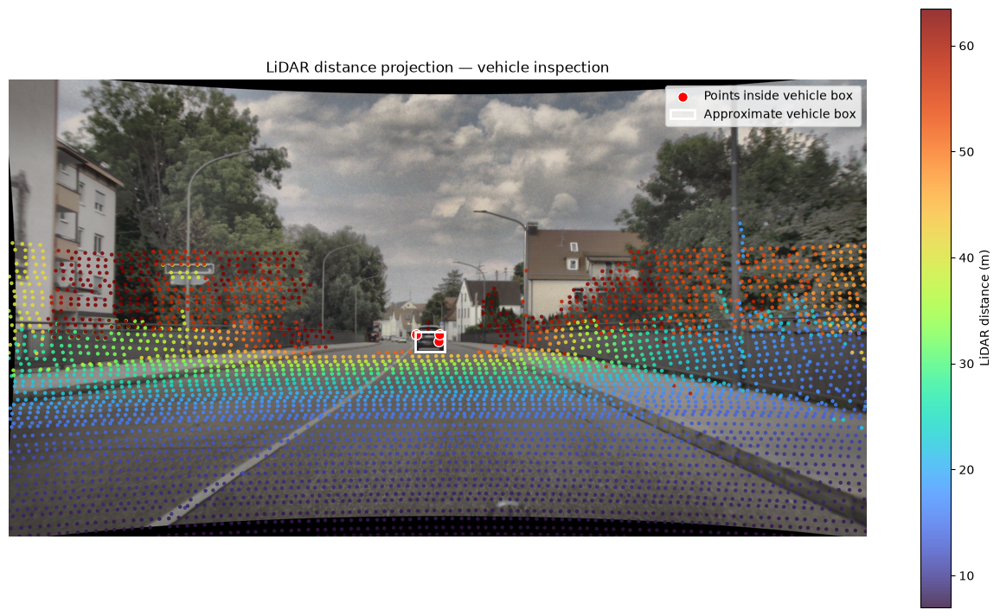

In [49]:
fig, ax = plt.subplots(figsize=(16, 9))

ax.imshow(car_rgb)

# All valid projected points, colored by LiDAR distance
scatter = ax.scatter(
    u_valid,
    v_valid,
    c=lidar_distance,
    cmap="turbo",
    s=5,
    alpha=0.8,
    vmin=lidar_distance.min(),
    vmax=np.percentile(lidar_distance, 95)
)

# Highlight points inside vehicle bounding box
ax.scatter(
    u_valid[inside_vehicle],
    v_valid[inside_vehicle],
    c="red",
    s=70,
    edgecolors="white",
    linewidths=1,
    label="Points inside vehicle box"
)

# Draw approximate vehicle bounding box
from matplotlib.patches import Rectangle

ax.add_patch(
    Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="white",
        linewidth=2,
        label="Approximate vehicle box"
    )
)

plt.colorbar(scatter, ax=ax, label="LiDAR distance (m)")
ax.set_title("LiDAR distance projection — vehicle inspection")
ax.legend()
ax.axis("off")
plt.show()

Nearby projected points: 6


,u,v,pixel_distance,lidar_distance
0,961,586,18.56,63.860001
1,963,571,26.32,63.700001
2,938,558,29.84,63.639999
3,937,620,32.96,44.020000
4,956,619,34.27,43.910000
5,911,571,35.56,63.720001


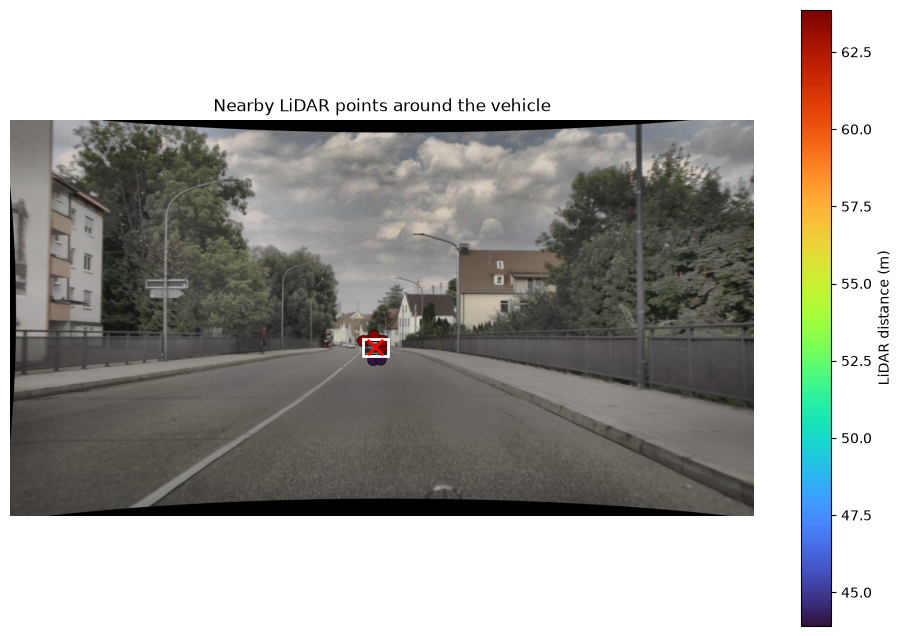

In [51]:
# Approximate center of the vehicle bounding box
vehicle_center_x = (x1 + x2) / 2
vehicle_center_y = (y1 + y2) / 2

# Calculate 2D pixel distance to vehicle center
pixel_distances = np.sqrt(
    (u_valid - vehicle_center_x) ** 2 +
    (v_valid - vehicle_center_y) ** 2
)

# Select nearby projected points
neighbor_radius = 40

nearby_mask = pixel_distances <= neighbor_radius

neighbors = pd.DataFrame({
    "u": u_valid[nearby_mask],
    "v": v_valid[nearby_mask],
    "pixel_distance": pixel_distances[nearby_mask],
    "lidar_distance": lidar_distance[nearby_mask]
})

neighbors = neighbors.sort_values("pixel_distance").reset_index(drop=True)

print("Nearby projected points:", len(neighbors))
display(neighbors.round(2))

fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(car_rgb)

# Nearby points, colored by distance
scatter = ax.scatter(
    neighbors["u"],
    neighbors["v"],
    c=neighbors["lidar_distance"],
    cmap="turbo",
    s=65,
    edgecolors="black",
    linewidths=0.4
)

# Original vehicle box
ax.add_patch(
    Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="white",
        linewidth=2
    )
)

# Vehicle center
ax.scatter(
    vehicle_center_x,
    vehicle_center_y,
    marker="x",
    s=120,
    c="red",
    linewidths=2
)

plt.colorbar(scatter, ax=ax, label="LiDAR distance (m)")
ax.set_title("Nearby LiDAR points around the vehicle")
ax.axis("off")
plt.show()

In [53]:
# Reconstruct camera-frame coordinates for valid projected points
camera_points_valid = (
    T_camera_lidar @ homogeneous[valid].T
).T

# Camera-frame Z coordinate
camera_depth = camera_points_valid[:, 2]

# Build a detailed table for nearby points
neighbor_indices = np.where(nearby_mask)[0]

comparison = pd.DataFrame({
    "u": u_valid[neighbor_indices],
    "v": v_valid[neighbor_indices],
    "pixel_distance": pixel_distances[neighbor_indices],
    "lidar_distance": lidar_distance[neighbor_indices],
    "camera_depth": camera_depth[neighbor_indices]
})

comparison = comparison.sort_values("pixel_distance").reset_index(drop=True)

display(comparison.round(2))

,u,v,pixel_distance,lidar_distance,camera_depth
0,961,586,18.56,63.860001,63.11
1,963,571,26.32,63.700001,62.96
2,938,558,29.84,63.639999,62.91
3,937,620,32.96,44.020000,43.24
4,956,619,34.27,43.910000,43.14
5,911,571,35.56,63.720001,62.95


In [54]:
# Recover the original filtered point indices
valid_original_indices = np.where(forward_mask)[0][valid]

# Select original point indices for nearby projected points
neighbor_original_indices = valid_original_indices[neighbor_indices]

# Extract original LiDAR XYZ coordinates
neighbor_xyz = car_lidar_points[
    neighbor_original_indices, :3
]

# Build a 3D inspection table
neighbor_3d = comparison.copy()

neighbor_3d["lidar_x"] = neighbor_xyz[:, 0]
neighbor_3d["lidar_y"] = neighbor_xyz[:, 1]
neighbor_3d["lidar_z"] = neighbor_xyz[:, 2]

display(neighbor_3d.round(3))

,u,v,pixel_distance,lidar_distance,camera_depth,lidar_x,lidar_y,lidar_z
0,961,586,18.561,63.858002,63.108,63.776001,1.321,-2.966
1,963,571,26.315,63.699001,62.964,63.608002,2.669,-2.557
2,938,558,29.841,63.644001,62.908,63.634998,1.269,-2.557
3,937,620,32.962,44.021999,43.245,63.576000,1.942,-2.217
4,956,619,34.271,43.909000,43.139,43.911999,1.378,-2.785
5,911,571,35.560,63.716000,62.949,43.808998,1.031,-2.777


/tmp/ipykernel_185737/2836476318.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


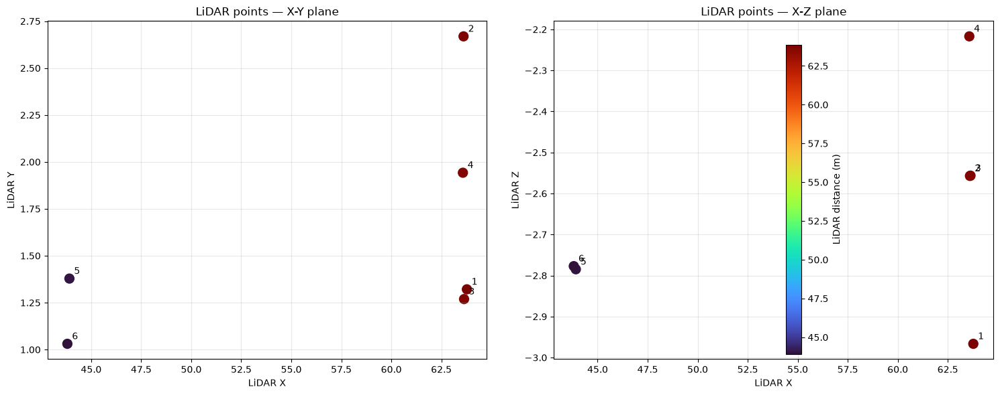

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# LiDAR X-Y plane
axes[0].scatter(
    neighbor_xyz[:, 0],
    neighbor_xyz[:, 1],
    c=lidar_distance[neighbor_indices],
    cmap="turbo",
    s=100
)

for i, (x, y, z) in enumerate(neighbor_xyz):
    axes[0].annotate(
        str(i + 1),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

axes[0].set_xlabel("LiDAR X")
axes[0].set_ylabel("LiDAR Y")
axes[0].set_title("LiDAR points — X-Y plane")
axes[0].grid(alpha=0.3)

# LiDAR X-Z plane
scatter = axes[1].scatter(
    neighbor_xyz[:, 0],
    neighbor_xyz[:, 2],
    c=lidar_distance[neighbor_indices],
    cmap="turbo",
    s=100
)

for i, (x, y, z) in enumerate(neighbor_xyz):
    axes[1].annotate(
        str(i + 1),
        (x, z),
        xytext=(5, 5),
        textcoords="offset points"
    )

axes[1].set_xlabel("LiDAR X")
axes[1].set_ylabel("LiDAR Z")
axes[1].set_title("LiDAR points — X-Z plane")
axes[1].grid(alpha=0.3)

plt.colorbar(scatter, ax=axes, label="LiDAR distance (m)")
plt.tight_layout()
plt.show()

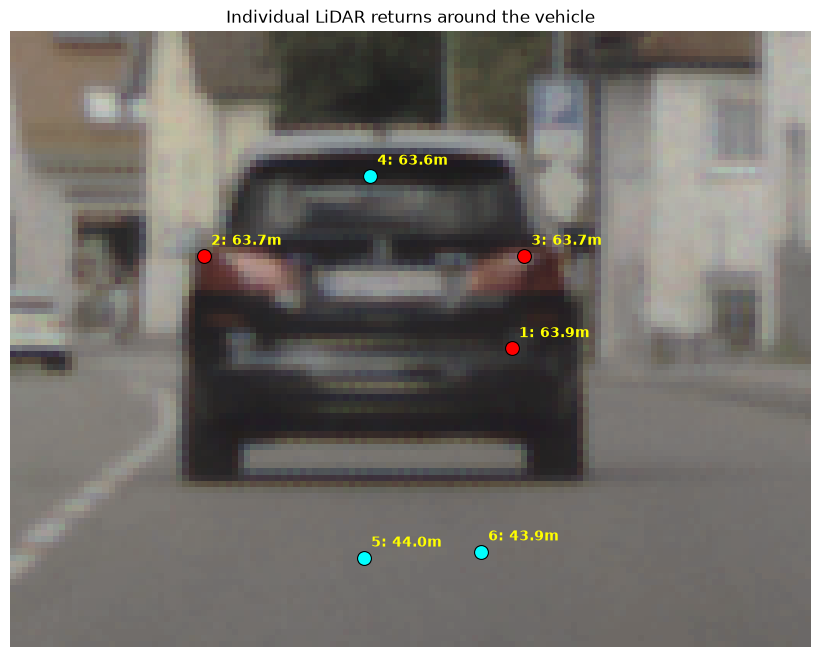

In [56]:
fig, ax = plt.subplots(figsize=(12, 8))

# Crop around the vehicle
crop_x1, crop_x2 = 880, 1010
crop_y1, crop_y2 = 535, 635

ax.imshow(
    car_rgb[crop_y1:crop_y2, crop_x1:crop_x2]
)

for i, idx in enumerate(neighbor_indices):
    px = u_valid[idx]
    py = v_valid[idx]
    distance = lidar_distance[idx]

    ax.scatter(
        px - crop_x1,
        py - crop_y1,
        s=100,
        edgecolors="black",
        linewidths=0.8,
        c="red" if inside_vehicle[idx] else "cyan"
    )

    ax.annotate(
        f"{i+1}: {distance:.1f}m",
        (px - crop_x1, py - crop_y1),
        xytext=(5, 8),
        textcoords="offset points",
        color="yellow",
        fontsize=10,
        weight="bold"
    )

ax.set_title("Individual LiDAR returns around the vehicle")
ax.axis("off")
plt.show()

### 8.3 Compare the same vehicle region with the provided projection

The same RGB crop and image coordinates are used to compare the official `.npz` projection with the custom projection. This avoids changing the region of interest between the two visual inspections.

The `.npz` stores numeric values at valid projected pixels. Those values are displayed, but their physical semantics and units have not yet been confirmed. They must not automatically be interpreted as metric depth.

Official projection: 2019-09-11_16-39-41_01770.npz
Shape: (1024, 1920)
Valid projected pixels: 4110


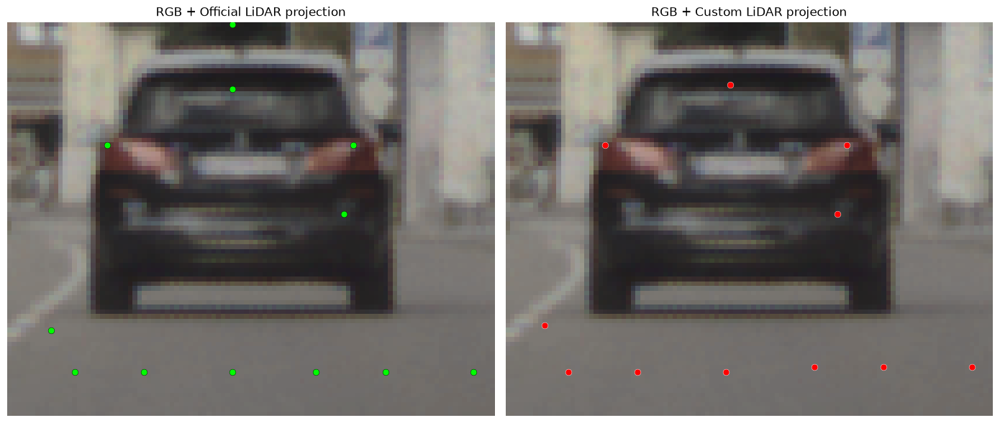

Official projected pixels: 12
Custom projected pixels: 11


In [60]:
# Load the official projected LiDAR map for the selected frame
projected_matches = list(
    PROJECTED_DIR.rglob(f"{CAR_FRAME_ID}.npz")
)

assert len(projected_matches) == 1

car_projected_path = projected_matches[0]

with np.load(car_projected_path) as data:
    official_map = data["arr_0"]

print("Official projection:", car_projected_path.name)
print("Shape:", official_map.shape)
print("Valid projected pixels:", np.count_nonzero(
    np.isfinite(official_map) & (official_map > 0)
))

# Same vehicle inspection region
x1, y1, x2, y2 = 890, 545, 995, 630

official_crop = official_map[y1:y2, x1:x2]

official_mask = (
    np.isfinite(official_crop) &
    (official_crop > 0)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Official projected LiDAR
axes[0].imshow(car_rgb[y1:y2, x1:x2])
py, px = np.where(official_mask)

axes[0].scatter(
    px, py,
    c="lime",
    s=40,
    edgecolors="black",
    linewidths=0.3
)

axes[0].set_title("RGB + Official LiDAR projection")
axes[0].axis("off")

# Our custom projection
custom_crop = car_mask[y1:y2, x1:x2]
cy, cx = np.where(custom_crop)

axes[1].imshow(car_rgb[y1:y2, x1:x2])

axes[1].scatter(
    cx, cy,
    c="red",
    s=40,
    edgecolors="white",
    linewidths=0.3
)

axes[1].set_title("RGB + Custom LiDAR projection")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Official projected pixels:", len(px))
print("Custom projected pixels:", len(cx))

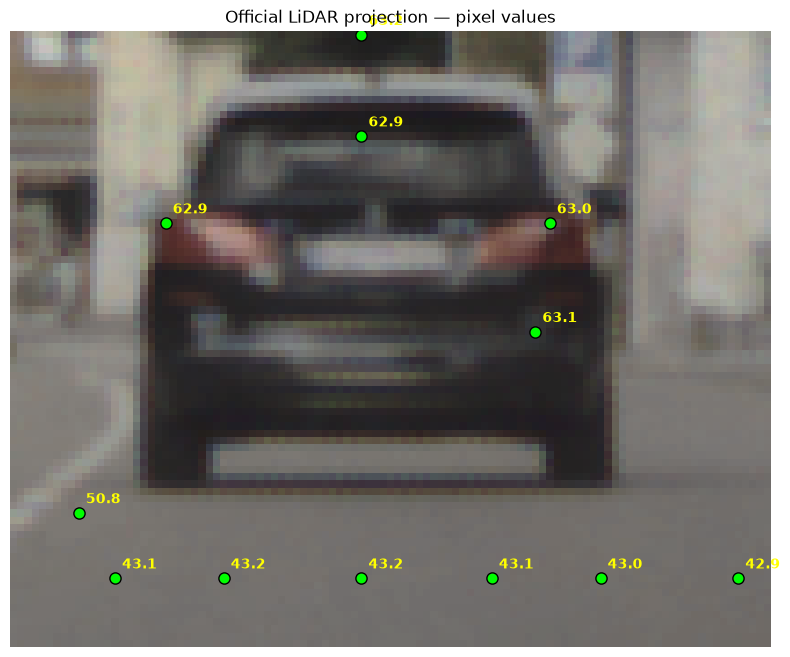

Number of displayed points: 12


In [62]:
# Extract valid pixel coordinates within the crop
py_coords, px_coords = np.where(official_mask)

# Retrieve corresponding projected values
values = official_crop[py_coords, px_coords]

fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(car_rgb[y1:y2, x1:x2])

for px, py, value in zip(px_coords, py_coords, values):

    ax.scatter(
        px, py,
        c="lime",
        s=65,
        edgecolors="black"
    )

    ax.annotate(
        f"{value:.1f}",
        (px, py),
        xytext=(5, 7),
        textcoords="offset points",
        color="yellow",
        fontsize=10,
        weight="bold"
    )

ax.set_title("Official LiDAR projection — pixel values")
ax.axis("off")
plt.show()

print("Number of displayed points:", len(values))

## 9. Quantitative comparison across the three validation frames

Two complementary comparisons are performed.

### 9.1 Exact mask overlap and nearest-neighbour distance

The IoU measures exact pixel overlap:

\[
IoU = \frac{|M_{official}\cap M_{custom}|}
{|M_{official}\cup M_{custom}|}
\]

Nearest-neighbour distances measure how close each projected pixel is to the closest pixel in the other mask. These are different metrics: high proximity can coexist with modest IoU when sparse points are shifted by one or a few pixels.

**Caveat:** nearest-neighbour matching is not a one-to-one point correspondence. Multiple pixels can select the same nearest neighbour, so the within-radius percentages describe spatial proximity, not physical return identity.

In [63]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

def compare_projection_masks(official_mask, custom_mask):
    """Compare two projected LiDAR pixel masks."""

    assert official_mask.shape == custom_mask.shape

    official_y, official_x = np.where(official_mask)
    custom_y, custom_x = np.where(custom_mask)

    official_xy = np.column_stack((official_x, official_y))
    custom_xy = np.column_stack((custom_x, custom_y))

    intersection = np.count_nonzero(official_mask & custom_mask)
    union = np.count_nonzero(official_mask | custom_mask)

    iou = intersection / union if union else np.nan

    if len(official_xy) and len(custom_xy):
        # Distance from each custom pixel to nearest official pixel
        official_tree = cKDTree(official_xy)
        custom_to_official, _ = official_tree.query(custom_xy)

        # Distance from each official pixel to nearest custom pixel
        custom_tree = cKDTree(custom_xy)
        official_to_custom, _ = custom_tree.query(official_xy)

        median_custom_to_official = np.median(custom_to_official)
        median_official_to_custom = np.median(official_to_custom)

        custom_within_5px = np.mean(custom_to_official <= 5) * 100
        official_within_5px = np.mean(official_to_custom <= 5) * 100
    else:
        median_custom_to_official = np.nan
        median_official_to_custom = np.nan
        custom_within_5px = np.nan
        official_within_5px = np.nan

    return {
        "official_pixels": len(official_xy),
        "custom_pixels": len(custom_xy),
        "exact_matches": intersection,
        "IoU": iou,
        "median_custom_to_official_px": median_custom_to_official,
        "median_official_to_custom_px": median_official_to_custom,
        "custom_within_5px_pct": custom_within_5px,
        "official_within_5px_pct": official_within_5px,
    }


# Compare the three previously selected frames
results = []

for frame_id in validation_frames:
    official_matches = list(
        PROJECTED_DIR.rglob(f"{frame_id}.npz")
    )

    assert len(official_matches) == 1, (
        f"Expected one official projection for {frame_id}"
    )

    with np.load(official_matches[0]) as data:
        official_map_frame = data["arr_0"]

    official_mask_frame = (
        np.isfinite(official_map_frame) &
        (official_map_frame > 0)
    )

    custom_mask_frame = validation_masks[frame_id]

    metrics = compare_projection_masks(
        official_mask_frame,
        custom_mask_frame
    )

    metrics["frame_id"] = frame_id
    results.append(metrics)

comparison_df = pd.DataFrame(results).set_index("frame_id")

display(comparison_df.round(3))

,official_pixels,custom_pixels,exact_matches,IoU,median_custom_to_official_px,median_official_to_custom_px,custom_within_5px_pct,official_within_5px_pct
frame_id,,,,,,,,
2018-10-29_16-42-03_00310,2397,2378,616,0.148,1.0,1.0,99.916,99.124
2018-02-06_14-25-51_00400,4071,4073,1009,0.141,1.0,1.0,99.902,99.926
2019-09-11_16-39-41_01770,4110,4114,984,0.136,1.0,1.0,99.927,99.951


### 9.2 Signed displacement

For every custom pixel, the nearest official pixel is found and the signed displacement is calculated as custom minus official. The distribution helps reveal whether a small directional offset is present.

Because nearest-neighbour matches can be ambiguous in dense or locally repetitive patterns, this is a diagnostic of mask alignment rather than a direct estimate of calibration bias.

In [64]:
from scipy.spatial import cKDTree

displacement_results = []

for frame_id in validation_frames:

    official_matches = list(
        PROJECTED_DIR.rglob(f"{frame_id}.npz")
    )

    with np.load(official_matches[0]) as data:
        official_map_frame = data["arr_0"]

    official_mask_frame = (
        np.isfinite(official_map_frame) &
        (official_map_frame > 0)
    )

    custom_mask_frame = validation_masks[frame_id]

    oy, ox = np.where(official_mask_frame)
    cy, cx = np.where(custom_mask_frame)

    official_xy = np.column_stack([ox, oy])
    custom_xy = np.column_stack([cx, cy])

    tree = cKDTree(official_xy)
    _, nearest_indices = tree.query(custom_xy)

    nearest_official = official_xy[nearest_indices]

    # Signed displacement: custom minus nearest official
    dx = custom_xy[:, 0] - nearest_official[:, 0]
    dy = custom_xy[:, 1] - nearest_official[:, 1]

    displacement_results.append({
        "frame_id": frame_id,
        "median_dx_px": np.median(dx),
        "median_dy_px": np.median(dy),
        "mean_dx_px": np.mean(dx),
        "mean_dy_px": np.mean(dy),
        "dx_q25": np.percentile(dx, 25),
        "dx_q75": np.percentile(dx, 75),
        "dy_q25": np.percentile(dy, 25),
        "dy_q75": np.percentile(dy, 75),
    })

displacement_df = pd.DataFrame(displacement_results).set_index("frame_id")

display(displacement_df.round(3))

,median_dx_px,median_dy_px,mean_dx_px,mean_dy_px,dx_q25,dx_q75,dy_q25,dy_q75
frame_id,,,,,,,,
2018-10-29_16-42-03_00310,0.0,0.0,-0.494,-0.495,-1.0,0.0,-1.0,0.0
2018-02-06_14-25-51_00400,0.0,-1.0,-0.493,-0.488,-1.0,0.0,-1.0,0.0
2019-09-11_16-39-41_01770,-1.0,-1.0,-0.504,-0.502,-1.0,0.0,-1.0,0.0


## 10. Results and interpretation

### 10.1 Multi-frame mask comparison

The three-frame comparison produced the following results:

| Frame | Official pixels | Custom pixels | Exact matches | IoU |
|---|---:|---:|---:|---:|
| 2018-10-29_16-42-03_00310 | 2,397 | 2,378 | 616 | 0.148 |
| 2018-02-06_14-25-51_00400 | 4,071 | 4,073 | 1,009 | 0.141 |
| 2019-09-11_16-39-41_01770 | 4,110 | 4,114 | 984 | 0.136 |

The official and custom projections contain very similar numbers of valid pixels in all three frames. Exact pixel overlap is more limited, with IoU between 0.136 and 0.148.

The nearest-neighbour results are substantially stronger:
- median custom-to-official distance: 1 pixel in all three frames;
- median official-to-custom distance: 1 pixel in all three frames;
- more than 99.9% of custom pixels lie within 5 pixels of an official pixel;
- more than 99.1% of official pixels lie within 5 pixels of a custom pixel.

This indicates that the two masks have very similar spatial distributions, while exact rasterized pixel identity remains limited.

### 10.2 Displacement pattern

The signed displacement summaries were:

| Frame | Median ΔX | Median ΔY | Mean ΔX | Mean ΔY |
|---|---:|---:|---:|---:|
| 2018-10-29_16-42-03_00310 | 0 | 0 | -0.494 | -0.495 |
| 2018-02-06_14-25-51_00400 | 0 | -1 | -0.493 | -0.488 |
| 2019-09-11_16-39-41_01770 | -1 | -1 | -0.504 | -0.502 |

The mean displacement is close to half a pixel in both axes across the three frames. This is consistent with a small, systematic rasterization or quantization difference, but it does **not** establish its cause. The exact pixel conversion and point-selection behavior in the official map-generation pipeline would need further inspection before attributing the offset to truncation, rounding or calibration.

### 10.3 Vehicle-region inspection

For the September 2019 frame:
- 55,602 original LiDAR points were loaded from the matching `.bin`;
- 20,026 points remained after the `x > 2.5` forward filter;
- 4,114 projected pixels were inside the RGB image;
- 3 projected LiDAR points fell inside the manually selected vehicle rectangle.

The three custom-projection returns had LiDAR radial distances of approximately 63.70–63.86 m and camera-frame depths of approximately 62.91–63.11 m. Nearby image-space returns also included points around 43.9–44.0 m. This demonstrates that nearby image pixels can correspond to substantially different 3D depths.

The vehicle inspection is exploratory. The manually drawn rectangle is not ground truth, and the points inside it have not been conclusively assigned to the vehicle surface.

### 10.4 Interpretation of `.npz` values

The official `.npz` array contains positive numeric values at projected pixels. Values were inspected within the same vehicle crop and appeared numerically close to the custom distance estimates in the examples reviewed. However, the physical meaning, reference frame and units of these stored values have not been conclusively established from the evidence gathered here.

They are therefore described as *official projected values*, not confirmed metric depth.

## 11. Conclusions

1. The LiDAR and RGB frame correspondence was verified for the selected validation frames.
2. The LiDAR-to-camera extrinsic transform was reconstructed from the dataset transform tree.
3. The initial projection attempt applied the camera rectification matrix separately. Repository inspection showed that the rectified projection matrix `P` is used directly with the extrinsic transform, so the implementation was revised to `VTC = P @ T_camera_lidar`.
4. The revised custom projection produces a similar number and spatial distribution of projected pixels to the provided `.npz` maps across three frames.
5. Exact pixel IoU remains modest (0.136–0.148), but nearest-neighbour distances indicate strong spatial proximity. The observed half-pixel mean displacement is a diagnostic pattern whose cause remains unconfirmed.
6. The object-level inspection confirms that multiple depths can occur within a small image region. It does not yet prove that the selected LiDAR returns belong to the vehicle.
7. The physical semantics of the `.npz` values remain to be verified.

**Overall conclusion:** the revised projection is sufficiently consistent with the provided maps to proceed to a controlled object-association experiment, while retaining the limitations above. It should be described as a validated preliminary reproduction of the projection geometry, not as a pixel-perfect reproduction or a complete physical correspondence validation.

## 12. Remaining work and transition to Stage 4

Before or during Stage 4, the following points should be addressed:

- Verify the official `.npz` value definition and units from the dataset's generation code or documentation.
- If necessary, inspect the official projection pipeline's pixel quantization and point collision handling.
- Use YOLO detections to define object regions and associate projected LiDAR returns.
- Estimate object distance robustly, while rejecting background points and handling sparse returns.
- Evaluate RGB-only, LiDAR-only and RGB–LiDAR association separately before making claims about fusion benefits.

Stage 4 begins with object-level association between YOLO detections and the geometrically projected LiDAR points.